# D51 · 프로젝트 ⑦ 오픈 해커톤 · 데모데이

**음성 AI 전문가 과정 · Day 51 / 51 · 4시간 (50분 × 4교시)**

> 🎬 **애니메이션(과제 브리핑):** [animation.html](https://imguru-mooc.github.io/AI_Voice/day51/animation.html) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day51/worksheet.html) · 런타임: **CPU** (GPU 없이 진행)

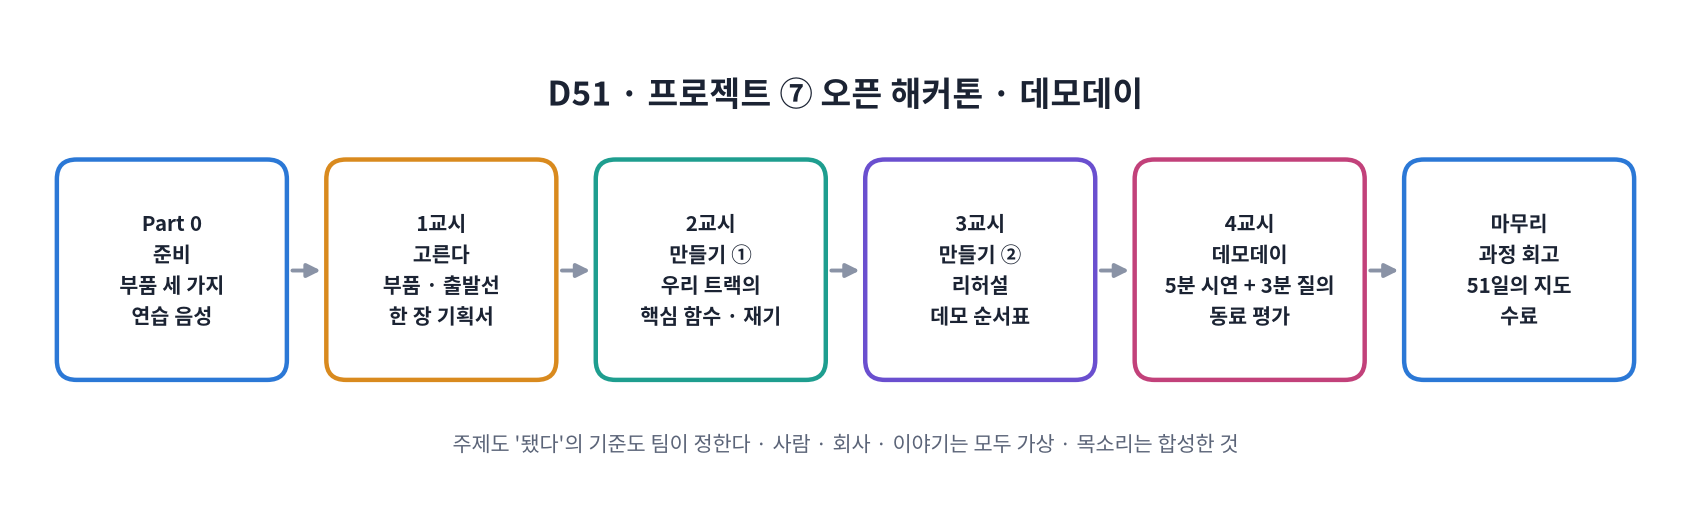

## 오늘은 마지막 날입니다

지금까지의 프로젝트 여섯 개는 **무엇을 만들지가 정해져** 있었습니다. 오늘은 그것도 팀이 정합니다. 3시간 동안 만들고, 4교시에 모두 앞에서 시연합니다.

| | 프로젝트 ① ~ ⑥ (D45 ~ D50) | 오늘 (D51 오픈 해커톤) |
|---|---|---|
| 주제 | 주어짐 | **팀이 고름** |
| "됐다"의 기준 | 주어진 시험 · 예산 | **팀이 정하고, 팀이 잼** |
| 확인하는 사람 | 채점 셀 | **보는 사람 모두** (동료 평가) |
| 남는 것 | 점수 | **5분 안에 보여 줄 수 있는 것** |

## 주제 네 가지

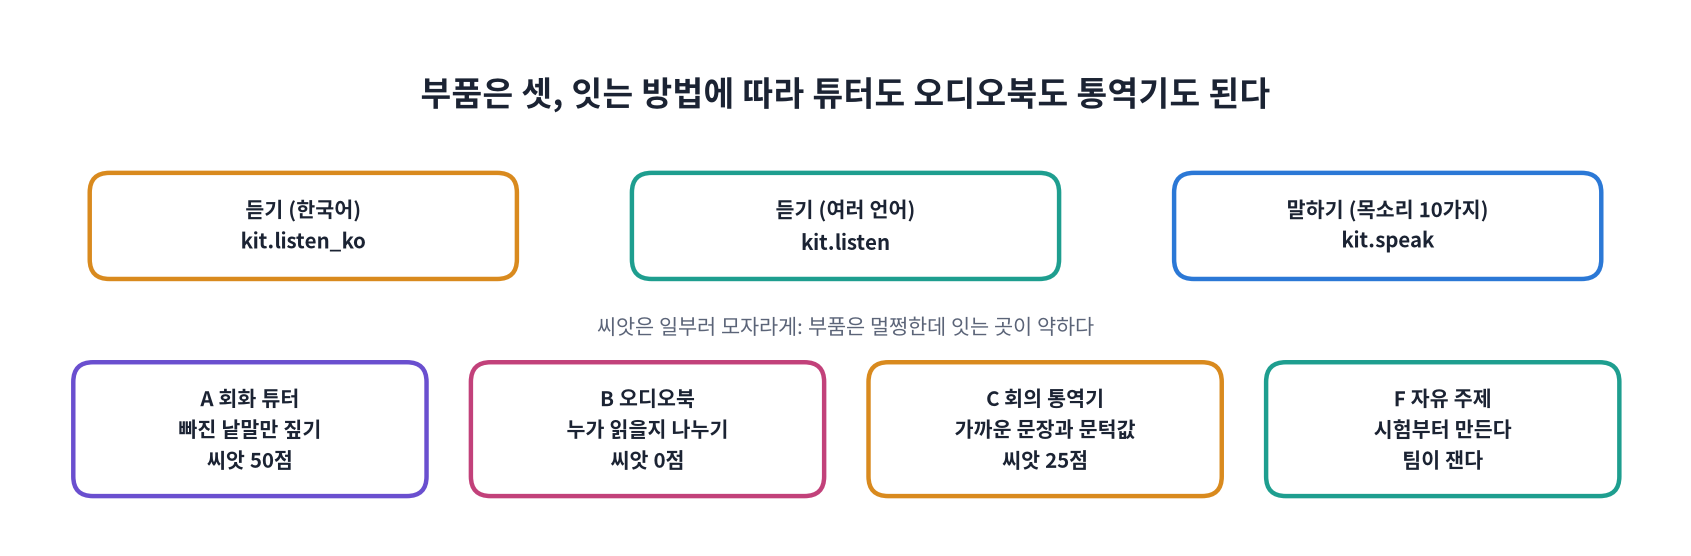

| 트랙 | 주제 | 씨앗(출발 코드)이 하는 일 | 씨앗의 점수 |
|---|---|---|---|
| **A** | 외국어 회화 튜터 | 학습자의 영어 문장을 받아써서 목표 문장과 견주고, 다시 연습할 낱말을 짚는다 | 50점 |
| **B** | 오디오북 생성기 확장 | 이야기를 해설자 한 목소리로 읽는다 | 0점 |
| **C** | 회의 통역기 | 한국어 회의 발화를 받아써서, 문장집에 똑같은 문장이 있을 때만 영어로 말한다 | 25점 |
| **F** | 자유 주제 | 부품(듣기 · 말하기)만 준다. 시험도 팀이 만든다 | 팀이 잼 |

씨앗은 **일부러 모자라게** 만들어 두었습니다. 씨앗을 고쳐 점수를 올리는 것이 가장 짧은 길이고, 씨앗을 버리고 다른 것을 만드는 것이 가장 먼 길입니다. 어느 쪽이든 됩니다.

## 하루의 흐름

| 교시 | 하는 일 | 내가 쓰는 것 |
|---|---|---|
| 1 | 부품 써 보기 · 씨앗 세 가지의 출발선 · 주제 고르기 · **한 장 기획서** | ✍️ `pick_scope` · 🏁 기획서 |
| 2 | **만들기 ①**: 우리 트랙의 핵심 함수 → 재기 | ✍️ `word_feedback` · `split_script` · `closest_phrase` 가운데 우리 것 · 🏁 내 결과 |
| 3 | **만들기 ②** · 리허설 · 데모 순서표 · 팀 코드 | ✍️ `run_time` · 🏁 데모 순서표 |
| 4 | **데모데이**: 팀당 5분 시연 + 3분 질의 → 동료 평가 → 집계 · 과정 회고 · 수료 | ✍️ `peer_mean` · `demo_score` · 🏁 평가표 |

**규칙**
- **데모데이 점수** = 동료 평가 70점 + 측정 30점. 측정 점수는 "됐다"를 **숫자로 쟀는가**(15점)와 **스스로 정한 목표에 닿았는가**(15점)입니다.
- 동료 평가는 다섯 가지를 봅니다: **문제**(누구의 어떤 불편인가) · **동작**(눈앞에서 돌아가는가) · **숫자**(됐다를 쟀는가) · **전달**(5분 안에 알아들었는가) · **정직**(안 되는 것을 말했는가).
- 자기 팀에는 점수를 주지 않습니다. 줘도 집계에서 빠집니다.
- 키가 필요한 서비스를 쓰는 팀은 키를 **Colab 보안 비밀**에 넣고, 화면에 찍지 않습니다. 시연 화면에 키가 보이면 안 됩니다.
- 실제 사람의 녹음 · 이름 · 연락처를 쓰지 않습니다. 오늘 주는 사람 · 회사 · 이야기는 모두 **가상**이고, 목소리는 **합성한 것**입니다.

---
## Part 0. 준비

D44부터 써 온 기기 안 모델 세 가지를 받습니다. 키도 GPU도 필요 없습니다.

| 부품 | 모델 | 하는 일 |
|---|---|---|
| `kit.listen_ko(소리)` | 스트리밍 Zipformer 한국어 int8 | 한국어 받아쓰기 |
| `kit.listen(소리, "en")` | Whisper base int8 | 여러 언어 받아쓰기 (영어 · 일본어 …) |
| `kit.speak(글, "ko" 또는 "en", voice=0 ~ 9)` | Supertonic 3 int8 | 글을 소리로 (목소리 10가지 · 말속도) |

> 🎬 **애니메이션 D51-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#flow)

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1분 안팎)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile sherpa-onnx==1.13.8
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, math, time, difflib, zlib, base64, tarfile, warnings, importlib, urllib.request
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display, Markdown, HTML
import sherpa_onnx
import importlib.metadata as md
warnings.filterwarnings("ignore")
SR = 16000
print("sherpa-onnx", md.version("sherpa-onnx"), "· CPU", os.cpu_count(), "개")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if all(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    def same(a, b):
        if isinstance(a, float) or isinstance(b, float):
            try: return abs(float(a) - float(b)) <= tol
            except (TypeError, ValueError): return False
        return a == b
    w = list(want if isinstance(want, (list, tuple)) else [want])
    ok = len(items) == len(w) and all(same(a, b) for a, b in zip(items, w))
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {str(got)[:110]} · 기대 {str(want)[:110]} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def tool(ok, mine, ref, name):                           # 내 함수가 통과하면 내 것을, 아니면 주최 측 도구를 쓴다 (아래 셀이 멈추지 않게)
    print(f"🔧 이후 셀은 {'내가 쓴' if ok else '주최 측의'} {name}을(를) 씁니다."); return mine if ok else ref

def play(y, sr=SR, label=""):
    y = np.asarray(y, np.float32).reshape(-1); print(f"🎧 {label}  ({len(y) / sr:.1f}초)"); display(Audio(y, rate=sr))

In [ ]:
# 📼 연습 음성 풀기: 영어 학습자의 말 8개(트랙 A) · 회의 발화 8개(트랙 C). 가상 · 합성한 목소리. (글자가 긴 셀입니다. 실행만 하세요)
_META = json.loads(zlib.decompress(base64.b64decode(
    "eNqdlc9rGkEUx/+Vh5deQtFdf6WXUnLKOYUeQg6rTnTJuiO7Y8SWQggeFjeFFBoiqRYhgilYGvILhfxFzvg/9O2mWWcTJ2hOO7rvx+d933uz21"
    "8SZinxDhIfUok1SNh41HIpPYtn13aCXxk8MsMpExaYbUKD1q0SWOYeAQOK9RrQXSjS3V1C1qBmEcMlb4NIrvEQd2mHqum66LC983UNIijtEUrX"
    "tIwSaiPM0KR1YMSyoEqgQhvAKOD74MEqBFxmMJPa72U2tR9d5PZImAjSxjD1SLtMNplUa1cx9gkqsU9KYNqwRTA/7FIHMzmEQJMYjvtEvCWMI6"
    "wgepwrHXHpybSSawvrLFHi2m/YQ5vcmllsYi5aitE82KmsIoz/oeIkmfl0ZdN5FcmnCnEImG4ovY0VEpeBWy80jObCBi5rv3C2shGSltHy6qYZ"
    "VbAo3TPtcii/AQWzXCYOuObnp6MumT43iwTCKHFxchFJKpNMK6fcsGETalhaoQlFh5RMBkXDKcVHOjJqmKzyzCxiKDTjCPkIIZ/NaSqEjyhzlR"
    "AWFIj6OswFg4Ft2gT3pUodhzZiiixrv6g/G9GFpKc0XUJKSglmZ0ei1+HtH8APb0TvHkRnMPvZAtEag/C74vQ4fPz6Pjv5zX2P+4MgKHPqrPJK"
    "d5lwfjuldblvMqHoeOLwUpx4oncA07Enzn5gounkSAwPgF/fYGIQ5/eYEd/E4FbzlLmi6yidWs+ruHo3/MoDfteaji+BDwfirov/Yb1/YPYNo9"
    "7P2mPg7Y449UT7doF4r4sgc6YVQxfjxKB+F7By0T8RvVZ4wqqxWfzvmJ9fTK/6Cr6VPGWu6LLS19flT6HMNb3uTy97WL3Hh0dh2cMDftjl/iho"
    "jT8AMWgppVvZWabLLrEXOMcoPMznW5yOsEui1cVGeWLSUau2kqfMlZtvQz6lUE30j4U/Cgf6dhTsnN/j/gT3LIx/MVFh2XXLknPll9Hghf77E6"
    "zpxWQ7/wDZkZBk"
)).decode("utf-8"))
_OGG = base64.b64decode(
    "..."
    "wDlwCurtQ8BTA2YMjDOlAIyXFFJIPTVM46kKAA=="
)
print(f"음성 {len(_META)}개 · {sum(m['n'] for m in _META) / SR:.0f}초")

In [ ]:
# 📥 해커톤 도구 상자 · 모델 받기 (한 번만 · 1 ~ 2분)
_LIB = (
    "eNrFXG1zHMW1/q5f0Uwq5VmQFr1Yxl6imzIGAgUESnJuKlEpWyPtrLRod2ezM2tJOErJZnGELS42trBsJEdcyxi4piLbsiMq5n6495/wUTv6D/"
    "d5TvfMzqwkYxJT1wXameme7tOnz/s5PZZlTTkT09OlIFubU//zd/XyYJ8KVzZ2ryyq3eWt8B8bu+c2VOvj5s6DOyp8/0x442JOtR4u7H6yaLcu"
    "39zZ3uRLrdsXd5dXcJPhXXjly3D5qtq5/yhcX1Vhc1vtbC6Etxek50ebra+/xN9wbUuFty/t3G92hWfvtG4ssXX3+hJuZIy1rXD5EUZsnb+i+M"
    "alizIKIFjb2rm/3o2HX4Xnllpf3GGP3eWvwubd3eVVtXPv/fDGB60Li60LG1nLsrpKlZpXD5Tnd6u6261KXrd61/eq3SooVXD/Xrk03q3GHd89"
    "crhbFUrFojyYcvwpXERvVxsVoMfxVbXW1TUyrIZU35He3t6u4yPD+Zdf571V8Qpu2X/en3LrNafHq1Zne/yg7jqVUnWy571SrejVK269Z9rDs2"
    "pPf2//4Z7eIz19R6yu3772+sg7rzxuoJmpkl/DywTT6jp5cuRxkzbQM/CqpYmegZ4g8HtK1eAo5zvS0zvY09eH94ePn3hjBK+fto5bOWWF17Z3"
    "HnwTfrpF/O9eAzbPr+42N61uZb0k7SsbrStX+PfhGdDAGjDNfd+9thzeuMVeJ9iLe7e2onbPPQivfoN2Nrwqr9+4GK6uq/AmycGa7zox/PrJV4"
    "ZfPw4ARq3WnW0+Rd/Wx9fCG5d4FS7+F96Rq/Vm68IdfbUc3j5jjakD/v0MNHqtdXNJ7X78IehEYffD5t8iwrN3Ns+oPvVnNRiuX8x0dXX9TH1/"
    "ZeFp/ad2thcAcMQlT3HkroJbVBNlEIztZ3JdXGjdDRr1Kn6yfmPcrlujf+jtOXa85/dOz3tYbM/ujZtjxBf+97lQGcCt23W3CKKeq0Wj4Ab410"
    "OjLdNtrtnlRVVAW7nkB3bdqU66dtlFQ0Y9p/oyGXkdtKxK3cpRpapywRtu3QlcG4P2mfH5r1Z3T4GjRnvHMBp/wHxxI0d4F3yXHmFKRojffFe/"
    "+S7eBBfZ8gBASJPqUX3mjt1xZTvqmSE1bkA0eCqM9qDb86rizNroypXUMxFi3nUqXoxYrxGQIsfiBU5METi/vSAP7V69YE8AFz2qd/b4CUiAqL"
    "FUVL3qF+igfqH6+vpe6M/JiM9hSNsKtxaxIZ56/nk1ePQokI1HG6R121M/l0ds6jct//mBdP45H4zFE4DPXRkz69RqblXASK4ULYll5QvcPgcY"
    "NsvjJeCXJTuYRy7G99/r8X32eja9U86P3+u59Ajj/9Jez3Kv5/bZa4MDTFHy7MCdDfDOVB1y00ALldDa/CxcboaXt8i40FKKQujGLdFInz5q3V"
    "5snV2hAGnd2gZL5RR4GxpI7dzdhLZR//v3uP9K1BQurmRVLwZofYVBN6+Jgto9s4Xnrc/X9FhbkUISfMXMZ4BL8bbXwPa2d1F35Fqwb7VMmppl"
    "H2uZDJoGSNf5X//mLRHtvZS977l1j+Kgjzde1eV1P6+DGXk+INdTdVdaDvOu6DXqvBmUm9IpaTnCG780y+sX5No95VZ5d5R3bmlyKuDdMd5VS3"
    "qiPgEh0P36BAS3HL3XZ8Bwy5hh3uzaDNjLz7ttaQd8hStnqJoinDeh4e9Al1ADhf95IVyDrD97FwaIwuaE5zd2z2+3Pl/FpsE24CsXxeqQl8Vu"
    "WdlWUDjYS7EyRNPQgNAiHG/ax9T35z5RXEMm3i6zMaNEbnbSDeyZbjWTEcKeIVUnpDHkMATyISVSWFEMZ8veDCRwJlt3a2VnwrWt7xeusfWQlc"
    "lk/Vq5FNiZsaeulLSRBmNtr5X2VFVUXsgt2sH8tGebvTOmk7ZN8rRNuoygtKY9S1W9gKjLv9WWIkWKIqcyXnBUNaeK1mljXs0/f7o63+PWvImp"
    "nmPHepxTkz19WZo1WY5qxe/n3xrl0JQkiVmzb1fL2M1hd8KbrJbAEdli3avkA8g7v9Cgcgy8abfqDyUn1I+ywSzJ2q1OwM6qDxVty1xaYLeCGz"
    "81l3z6roe55KG+wrMu9S/+g8zMk0mdgj/UD4pyKrWym6cUHRoZ7lZF1wF5uhAWlaGjvQYwWJ35ihtMeYUhaxL8XZjL+65Tn5iyUrImQpnZPioC"
    "t8pNnGtzIMxqYx9GknMTRGQbZoMBvvmR+n1k4CruC6kNXYRHlxczWZhGS631DbCt8Nq993NkuJi7sF9CNy8qH5f17ASWGrh5bT7bGl4/60xMuL"
    "UgP+OccjmVzaVXa9kJrzqB3lXqlFHcU+T59uGjvb3SXCx7TjDQn5Ebx3fqdWfOntvbpF/r6+98byxDsEBttUaQL5aqJVBWwcAEs7zsAt6Sn+fm"
    "zFFs4VZTQwS+n5btFB/o7TfKAZqy6FSq2ZkU+gleGcp4CNRmJQTh1Tutv8IJ+3R7z1b8VvsH4sbsvwEcj/K3arFJGJC/7zqW+n7hC/X4DTqYk2"
    "1rxtLAZvZjaFBXoscevqSvtZcxjbNjx1xnnU54SPPPc5E9pjEhBRIMud8LpjH5wr/Ml/KvLTz2TpqSIsRBw5l0h3gB99Pxp4cskUIT9dI4NWaK"
    "zzNt3khj8SlyyUD/P8Ule14TJnk84ftZTfRZ2jEJss+PvPP2G6/8OqlDsPvOtLHdNB9M01g55ZUm3KEXutnuFob6soAB7FLzh460mYR6HDaCiQ"
    "xAnY/E7rAaeCxrRCxBFhGWkPlysOr/rI7tJ8H6jqjp194zU2Vp9tEYCa9fCe99I1f3VsK1JWjdpdbl9QiiW4/ENb2AuMjllEV4AI9Nu3NATQIZ"
    "3VyELbBhS2QDbEFIRrcIRoxdDAbl+xFjakznki6LhQDBvqqY/yr78+vJwG8j9S0GIE541WJp0n722dPTorZNgAJq+9S8JVbSNLaPUxRKE4G9h+"
    "8KDTHXq3lY9+zh1Yesvc9SvE6E5CMJYSXvUt1OuXwz7/oI9jgybueTxwqEU56ZwFykQQj8PCNJQ0Rilld42ABOyAOlasGd5ZsdD7LjpWpEy2CU"
    "ubLLwXEjDZlsKXArvp2Zz6RgoZbmTo0duCP2/o/NzkiYaGj/LskdbMeOhiqd4ijTBmmyA4xfuVVX75YZB9JgMuuX6Fq2qVWekVLxNEm3fM6phH"
    "LNG5qK2YKdrTvi0JD64TPwZz4GxdHyUWMHurWqnUvNL5MYgeyTkGlOVltPfkp+JVki6iH2Fb3MkeE0W1BJKX+ihIBgxLSlyapTTnXitPox5Z4e"
    "sOaVRahSJKdmyQC8YK7m2vuBZNh2FJzM7Z9LWW+JtsiE8JwCLL3A9iYn8+NzAVcKO9DpMMrpYhZpvSCm6RelCZD5VDd+Mcs9t0te9iW+//rb7b"
    "Fo9hLSIcvAaQHFju+7HBMvE1tRNKVbvNxROPS9cSChQiFAcNooneCiRmu5Gtz6yqhVtcag4WoMnOi7F0UHAjPQlAWvAiVTdKBH8vXqpE1SQa9S"
    "wRob7cuNMWzBAE30qHcsQbRVUZp+gFGceiFfhXJ0yhLumMjstwEv4o1nZWL/j/WALRW64RPq2WdVP53wvl5ecjK/WrfG5AmfRz2rumeCuBhgEg"
    "lYweilYNSaE47GmM+p6v4wJOI9pWCfeM/T9RlN5P64+Mb7R4WfenjThwzIF/FnHHkIO3DqMJARnYSvUkjYvgIYnNm1JiDSVi+0O1z/ldbieqx7"
    "4cEjCIC4jA4JtM48YsSGAYONBShbOx0HoEu8tJAOFHy7Ht5umtfFkHh/DbFjuM0MI4fL56HR22GBQEdRNcyRJ29gj25T8YOZKJo2k46FBRlKnp"
    "L6tyFlYq3oNjVaGqP8mYljWm7x8Ygy8MRRFN0HEMVPdO8XYRa4ZE7KiXaUjyFCiEWtpyUPkh1x/9iAXnXfcoIJCHz714ghdcs8EGGNwHu3UZ0e"
    "etVBaDIjjk2F/eh6jpe9iWkospxMlW3UChIhlhCjw8gxKf7HIcdYKRwvwkjQEF1+CoxcREZHlGfCb9UEqzMCOeSIroXnHzAbQQJBwOjozuZqeP"
    "Vi2FxVhyKj7Oom+uwurxsSOCQ0sL6MXMfujUUkrK6HVxdhAWLA/UzC03VvBvK2RolYgDidQLJnPnZz0ZaOMJdkQQJ1Wx7KFlENBhJpsuTeEoow"
    "7qGRHN1iqxpJontRmshVPFpQn8upSU9C2zC67ZlMHI7SNriV7f7lM1YillXUE2ja4SyaZhKB6Fl6GOoV+YHOpwpx40mKki66tQJkiDQDYeTzVa"
    "fi5vPzVnsQIiMSbKcprXOyDIpt5oK+/mr30qoJ25mmNkDpAC6aBUImibA9cTyQ4UUx6LMMxNgAT3Bo2eHVc+Rik1VqXXjQ0ZOTVUo+7Im9LyC7"
    "hYAxX/h+9QOLdCnLHlLtlyRQj/a1Jb7gTVu5vX2MeScs2KjY9VH2G5M9qEs8EdhJMcdpi48wlCYwS1MY7mu4ETKTNsaN+3qhlzD08zrZwZEYaZ"
    "9PsYwPUyiSIASpk2kMi9jAb4YB8BWTWpVo+f6s0hkstX5F/xTxsPFn1MkpXM2ATmBeFmGAZwV1ZGhObjD2K88rkF6z6k2hc+VMOsAF9DWGhEsY"
    "cJueM9L2p1J9L4nq2z/h+TQ134njIyfFqmWSvbmB3XtByGsdOgs3iPJZzDc8ZLob94OkemQRbiyFt0jZvbx/uBBe/VC3H53vzIZevivh8u3WnU"
    "cS0I7T5ap1bxHar2vk5NvDr78iaWC99+H6QusDrHfxHgY8hJ/w3EcggkWIQEhJpZslSbL532S/a1ew/ybRrjTkzLxCV7bOr1Butu4jH7IpYedP"
    "FxN9rda9pfCjL1lfwBegWVtNPGbKn/UCty9xOmZulx+xD4glRoX0v7eK/yiOkWaBCBef+vIGBHNyDkh11Awg7ULFjVVkk+9tLiBXq1rnv4i0+n"
    "ITsxxKWfCH9JKk/gB6gutBhvnja2rnwVZrfSG1nuaidDt/kfoA6mTn79ut9b9g8Gcsuf7rHdoX6VV89n64+kjwswTb5EEnimQsQrmzva1tm/dT"
    "wLYurWhZt9K6saB10yUOCKNo5y4jhDubif05pH1bhnJbmxuSuTp3sXVhhTtttRZ1dQfEHGyr61d+aamY1iSXDjHM5QOdl1db69vJbV9eDTe3Ve"
    "uTDe5ZTJGywM3vzIvh1a3OzVljAHMDOVB57c5WeB5JtLVHzKBdWEzOT7yiLCCy7m5+Kbt9dqsF8kiPCVxxx0yMRduFhBcP1jdAKVhY1gIe5oXy"
    "f5c/Ofybk68dQP2Itxm+lHKEn4oTLMn3Gqbv/vF8oV+PAf3RXLInN2EnhE73P8NDHRA9KQvtQcRjGKpz0f8Ee/3Qun+I+TpA+HGsaGXGDmZGEF"
    "5bzHPoPazZOfdPyah6srae6f5hzt2b7doX2idlawNBCiVPwufEcRxOpoOpvTEdFpqAo73XtYSpA85uhve2OLCGmWRFy0dXqAnHr30H2JOB28h9"
    "SaxTQtxRtvcQhA7myWSSbtwB4NSceiDBfde4j/VDlj36B2vs2QxHkRKAF+NKlRd1pNxlfCSaPFmyUUv7UTJ4smYDr9XiSHwiAka7rJZTSBkEpW"
    "rDTTaVWJVCW7Y3HRNLhCkSeKhl0mFMwkVXgHBx1bk9AVfOzg7PtFckBmD0FsBqr5kPDy6PsU3HNhh7CmXGPW868h6TBQcJ6y9yHll/GNckCst+"
    "vilFZYeNbLU1ZRhS6SY5ZXa+XRKxEfuPQq5bT81/DEpB2dVkQeQYiy6KIef2dQJteoEsAOLveJyAzMQRAOMDmowD609oq2ae2AG0jQNIPuhwAB"
    "NjcDYfzkswG0FuNPKoLGqsIxOBUDU3HDDZKPNKgspZQTXjJMpgFutiiCJNdmlfM95FiFuDQEu7kcFs0iUkdBZEEnZmU/t8AoX2CPXmP9Yx1DDD"
    "wavt4xG2G/8fXcEK2CPvNAolj4xg++5kxa0GvpZIQzrUU3MavjvUmx0YTOTdEryiETG6H/V3M402JnpFnrKw6sKGKaxKlO9CTeJtBhq5NUxtP7"
    "xGx4Vq6weybhFrEGBWVPEHiCPBInfg1HTgWCctGSuW1QAlI8OZVPz/xb3Vf23ijPCSKAQ0hX0mUUmykQwl55egDV/mzWgkxMYyBn34BVxjyQ3t"
    "yM5icAl4cRIhnHZxQjpn8RN5wCeiQuxkMe9T9X3feW34+MgrL7399htt81tPKEbf2S3YE1KD/llTqscRbRCzGz83LqHSW9sG5LWTUy6yCS7U1C"
    "TkmShPBBoGoNYqWSTmK14dRJ8Vu2VlMTy7iYQvTY6d7UWmadceGQFN8xyMzgrl5jZaOPQ7KLoD8n0IDRVgmvFGATuroNOranxOvVovFZy5rMkZ"
    "UqjArQblNoms1u2N8OGqmAsXvlG7H2HYRyiVUfQGEtYNpxlxkItSKNCZUQx5ID4yAVrDjCVf/bGBFSFlaCwnJpOxgJ27W8a4bDVXxLhc2Lm3nh"
    "r0TTc45KuKdwriqgo8yAKqoiWgGtpAA0YGcmC9obqafIor4ADYb/1tG0ZZ57i/ddVMqVxGoUXZmZNBy06jijpZIATSQs247rTGNlj9DjbuxiJA"
    "DS+sEzHwQ5pAB0YD1jnayx5W7lTn+OYUyhUQFEaw2adG+WUMIo3DJanwNxT5mbhgO/cfoKac1WwdIL6uIfSnnLorECIi7dZLiFArp4gr/UyTjE"
    "EsDNdvOQ+UODX18pb2r75KrbvKvCUwCWGLrB7AVt5MVfbGAAqdd35FtckY1Tq0FOC70HH8dg+gDIlhkxwAK6rcAzlx0xKgieOG6tGHi6gh0Ocl"
    "FlpnV1ERT4KFKA03mp30dKLhg+6xzgkP6UXEz8ASKMuok5gLOnVZppSswLibiqHn1ix/R3ePDHhvGXb9LjIja1R+C7C2Fe396FRFxHhld9Ipg2"
    "odJPV8CLNTJXeGjEgM03asOwz0kRpurAudfXiHwfMLG3Q6OOO5j/bZQE27AVQT6MGfYrJyHNBPixkYmaQEHH7828PDv6PtOwI+R/bydbQ3ygWT"
    "KMBmo3SArOQEWRWxM+gWUXeJLGatpIMgmYtUwTATp85sXhLb0IC9+2SjknFo8Yx0kSrcP8ZP5YYRU11cGgmblUuSroKftgyduGSELJ3BvV6Ftn"
    "hqQiJizhvQqCBM/XCGdkSiRDg2gdrexkTZwzvBgaszKxtHH1hVNK218j+WPRbrw+TsbU3IvqlS65QjUUct/Hg9lxwYirGeXCCbxH6rs3g+hkhr"
    "PkJhlqH3syPVs3cJDGALOttZHy03EH9gDvOosdbDlfvisuv90uLU7MOnJr9jtzeTyufqOeENZgUX4i1baUcFKDS07Zh5Ast+pu6xlOenSRCxlt"
    "LkiJ48O1Q0yUFj87d1dCaJ5SfzAR6bA2pbUdPomkiNBPVGMMV8/7hTMC2QK2Rm0oF2A3HjTT9hEomOu84D8aHvRLmlA5JHek/xoL10wS/gQKu9"
    "Z8tp+EcJIMApMArV0rFitilDEY54BhLO1NHg/utbbaEgPuTmlzp8zxMPmo0MNLVMm+mSW7F/yeI+3geQK8Cg2PwzhlpWWl//w5CttBPHbbckE/"
    "klHgq1LLThEn+frm8iNE/HSg/FWTrH+jEezNM+wrW5e/2j9glFuUqdKHvqx7qm3InpPO1Jm3+SJYwEBcrY5KZZk/D5EgOUPJby9ZdI3kg27v59"
    "sdkkBA2KpMRRus5h33prRMa+XddvrbTPStitb5vieompxuMrmpYykVDSzGhk0mS7QB+VfgRbWGRaZ+j9UpXlNYh5saVbSl0yCUmeCC9N2hYNBy"
    "212jeQBFZ4XY7ZwP7QRBgxuPTJ8Tn9xNYXzSg1D5bUVntc9MgBYX1MW3FRsj7y2DEeu+R0sYuk/cTzeVUi7Ne3QAYSwD+70h6XNCjcbVvwI+sa"
    "eob2oOcOyzVPql5et8RtTHbUPXU0l0Pu7ZCGjQ9hX6A/A7SXufWM/qJOQSYwHvUhMQqXm7Se1h6lIpWwLj5dD1futL7Y4ukk7u/OvaV9l1Kre+"
    "Nlt5JaTV9/Gh7TJ8dAfDIaensBvpSEga/+RQygh4u7/0HyFCQCYBHCCS2LCnsGVenpv38mY+DhuQ8AYs4x+BoSQ3KGYOwEdRW1jsqISuBCihlW"
    "zgzIPQzqZN/ZiAzZdtqiEqJJWpEqTKsCa5m/sCoaOIVEE4QlMbNa+or3X+zcmghKRoxxOvmWGoBNYRbUbZ6ZUIdELUFTmE1+MBt/9Wx66W7ZLB"
    "COkD07qiEaS05/4OyPvhGu/dT4Kyv6GBOntznK0Ml6w81wUzQZ65B7u3/k32g4KnoLUJpXL03oDTg9f9AGVJJIjSipoq0RwXCblLAvh6Vb8nXd"
    "0xR0MMIP687UMmc60a0hQpqydRE5ko1DEvW/D3q7Q/fHnOASZSpCweb8GSlTkBqSnc1PojKo9MEXzJGwkGslyGKoHhgrEYblHGKDNY+5dkVj2S"
    "0GpqjRtMa2WlG2K9qepBlcjLY1FZ/GU8EVbTQZtmdIeoIyx9KD+nCCcOZktLh3nmh34ikAGIpBh4yQLuaU3YM2TXFoiybIZPZAyMdkAMLy4wDd"
    "E1cnRuuNap4n7HUpLzm2UorSHIEXwHPURoUvi8rDFtYykXW/yVGlr5igNooe9Js9ZrTkBrpuPS9ll+OQAB6jmNQX0XFnY1mPj2r7AiU4o2zWjC"
    "ZxZPOa2EajFh1lS6rvxL8lAWtHt6oSY6QkFOfIRVDH+i7KDmlzRps+pU6zJ23e9GvpU5Lm+EwuG6WgNZlGKrg4IyrQ2EQAK30dH3RR6DgsLpP3"
    "Zl+ALSUwsHM0q1zzZhCttLdwzpaX0VC0t8yUMh1KCXlkDtgAjuk6D1n4ZoSVPF67yuKtcHGVAQWy63eXdM7MNnWa1OFgTx6N5WEM/ZBD0f5gGC"
    "Wq55Qh9hzDNPxgQEiQO+jWfLchiwBQH1JAjNo8p6w/SeFQJquPCEC9BsWeozx9OeXOFkqT9I3jQ+E1VldOo1wfHqtXmEtjssi1nmbrvIypvxuR"
    "HT9y2AzNz0lkGXsBgfg2DwVkC/h2hG9zLJ4kJE7zDsrHS1HdZAdQcLsBmD5KEx8Ma1QFLD4zAPGSIW/8RDmcuBKbD0dzh8dIQTYhPkklh9+XrI"
    "yJo6AD2mlv/cm0qfC7K8ijisFBk+Ka0Q/J5ct7A2P6CxpZlpr7esUE16y5jRKzBnlpENXZ8api/Cfpii1x1opBFvk4iNDP37albglBL8nwIvB5"
    "U/IEl66Yb4Joq/CDC6IHZBk2PvTA09dUercX0Lt1dpuGcKJ4l+RDoXBaW5857a2ZwWj+f3WFiPhCvj+h7Un0OS53zBvxrnVlk5ZX+2Rt+9MZRp"
    "XmOsoSTTYQWWxLXC2f4wz28jATRSrvwIRyaxQkqrtY/sWT02WWhs13eIEHwR/e/WBnc3H3yqMU/C+l4Y+rwgz24PMgToJXO5ag8zytzU2Av+8S"
    "Uis41p89llzAseQC+p50AcwUdWD/RAr6KCZMuxe2gHFv04CLfWAydQlwdYArgtfcxfCa+wji3nkt6cc1uYhyeDy5GA2BAMiBm4JiD3xwBv8NdL"
    "O87/BY9wHrR8cB6dgnf/vH5pMIPAic1O4fCE4baMwyKOPrv48FRwPdL32fEJz2Xj4ZLBqQQY2dvbB0otEAvW/fNtyD0aD8D3CnzJdRkbAWRWWg"
    "NbB4jiImMKhpJvsk3YNxquMTb/9meOQVnfzug9MtEpWfm3l5UOLf8dE/870Bfp+AJQa3F3aZ3orqDWRhNx/tLi3RY+MNy1FWyJ1cxsMms+pSEN"
    "MfTXKEk+A7C4m4lhwIxjl21u1+dtG8HB0Q5qAPVsP1MwyGMs8HXueXax42TUcd7EiX8djWQLwoWVWfLKt9LByzKUK9tg3x17qwllP6A0+svseY"
    "b3rDx/XhCri/F/UKDscjyhL69RIiMWrjBGEK/p1737X++qEAeGl1d6UpwyEHtL4aXoPkX914LPiD0WT9An6/gP/mm2/RTQhv/AUT5tS/84yaOj"
    "7J7BucdAg8HQKS+itcvXXiHQ35kXgwgXxAIA+lJnpns6nxsLV7pdliUdQ2FpE8Jo+B3inVXCR7BTH4usYbpcBsNfaiE/AXorkGBPCBwagqD0Gb"
    "8xsYG5f3BBnhZ9/ygyMyKZLo20w38nEMF8QfsnLmzAt3H2lp6Nc2EejVHY1nlNUd1vvSvIzqFUETAkzmADpePM7aAQVEyrD3Fhl31xG09uZjJ1"
    "O00bnEY9GEh2WJh/USr2/hsx+5KPRGnhG9JEvi8q8JUWwthNufszj7vvYJl2V94dWbjNE+p7gJn4PY14iM7y+t6xX29cYzyhIHZYkdfT9Hy/eX"
    "bmG9a9sSPrmwuntV82TzLp1+Hh1prhvSxJEhIvW6fMOstb4I+yOSUyDQ5e8619wXCwkYznsn/yK39wtsHZ9OQ4Fb1/8BbTsgBQ=="
)
open("hackkit.py", "w", encoding="utf-8").write(zlib.decompress(base64.b64decode(_LIB)).decode("utf-8"))
import hackkit as kit; importlib.reload(kit)
print(f"도구 상자: hackkit.py ({len(open('hackkit.py', encoding='utf-8').read().splitlines())}줄)")

REL = "https://github.com/k2-fsa/sherpa-onnx/releases/download"
os.makedirs("models", exist_ok=True)
def fetch_tar(url, folder, label):
    if os.path.exists(folder): return
    t0 = time.time(); tmp = "models/_tmp.tar.bz2"; urllib.request.urlretrieve(url, tmp)
    with tarfile.open(tmp) as tf: tf.extractall("models")
    os.remove(tmp); print(f"받음: {label} ({time.time() - t0:.0f}초)")
fetch_tar(f"{REL}/asr-models/sherpa-onnx-streaming-zipformer-korean-2024-06-16.tar.bz2", kit.ASR_DIR, "한국어 받아쓰기 모델")
fetch_tar(f"{REL}/asr-models/sherpa-onnx-whisper-base.tar.bz2", kit.WHISPER_DIR, "여러 언어 받아쓰기 모델(Whisper base)")
fetch_tar(f"{REL}/tts-models/sherpa-onnx-supertonic-3-tts-int8-2026-05-11.tar.bz2", kit.TTS_DIR, "말하기 모델")

ALL = kit.load_set(_OGG, _META)
TUTOR = [x for x in ALL if x["id"].startswith("A")]       # 트랙 A: 학습자의 말 8개 (target 목표 문장 · miss 정답)
MEET = [x for x in ALL if x["id"].startswith("C")]        # 트랙 C: 회의 발화 8개 (said 한 말 · truth 문장집의 문장 또는 None)
print(f"트랙 A 연습 음성 {len(TUTOR)}개 · 트랙 B 이야기 {len(kit.STORIES)}편 · 트랙 C 연습 음성 {len(MEET)}개 · 문장집 {len(kit.PHRASEBOOK)}문장")
verify(len(TUTOR) == 8 and len(MEET) == 8 and all(os.path.exists(d) for d in (kit.ASR_DIR, kit.WHISPER_DIR, kit.TTS_DIR)), "도구 상자 · 연습 음성 16개 · 모델 세 가지가 준비됨")

---
## Part 1. (1교시) 고른다: 부품 · 출발선 · 한 장 기획서

> 💬 **쉽게 말하면**: 3시간은 짧습니다. 요리 경연에서 가장 먼저 하는 일은 불을 켜는 것이 아니라 **냉장고를 열어 보는 것**입니다. 무엇이 있는지 보고(부품), 지금 상태를 맛보고(출발선), 그다음에 무엇을 만들지 한 장에 적습니다(기획서). 여기까지 50분입니다.

> 🎬 **애니메이션 D51-2:** [주제 네 가지와 씨앗](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#tracks)

In [ ]:
# ⭐ 부품 써 보기: 말하기 → 듣기를 한 바퀴 (한국어 · 영어)
t0 = time.time(); y_ko = kit.speak("안녕하세요. 오늘은 데모데이입니다.", "ko", voice=7); t_ko = time.time() - t0      # ⭐ 글 → 소리
play(y_ko, SR, "한국어 · 목소리 7"); heard_ko = kit.listen_ko(y_ko)                                                    # ⭐ 소리 → 글 (한국어)
y_en = kit.speak("Welcome to demo day. Let's get started.", "en", voice=3, speed=0.9)
play(y_en, SR, "영어 · 목소리 3 · 말속도 0.9"); t0 = time.time(); heard_en = kit.listen(y_en, "en"); t_en = time.time() - t0   # ⭐ 소리 → 글 (영어)
print("한국어로 받아쓴 글:", heard_ko); print("영어로 받아쓴 글  :", heard_en)
print(f"소리 만들기 {t_ko:.1f}초 · 영어 받아쓰기 {t_en:.1f}초 · 받아쓴 글과 원래 글의 차이(CER) {kit.cer('안녕하세요 오늘은 데모데이입니다', heard_ko):.2f}")
verify(len(y_ko) > SR and len(heard_ko) >= 5 and "demo" in heard_en.lower(), "말하기와 듣기가 한국어 · 영어로 돌아감")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
y_ko = kit.speak("…", "ko", voice=7)
heard_ko = kit.listen_ko(y_ko)
heard_en = kit.listen(y_en, "en")
```

**해설**: 오늘의 부품은 세 개뿐입니다. **말하기 하나, 듣기 둘.** 51일 동안 배운 것에 견주면 적어 보이지만, 이 셋을 어떻게 잇느냐로 튜터도 오디오북도 통역기도 됩니다.

- 부품은 모두 **기기 안에서** 돕니다. 키가 필요 없고, 강의실 인터넷이 흔들려도 시연이 멈추지 않습니다. 데모데이에 이것은 큰 장점입니다.
- 그 대신 **작은 모델**입니다. 받아쓴 글에 틀린 글자가 보일 것입니다. 오늘 만드는 것은 그 틀린 글자를 **전제로** 설계해야 합니다. D48 · D50에서 했던 일입니다.
- 더 좋은 모델이나 LLM을 쓰고 싶은 팀은 써도 됩니다(자유 주제). 다만 시연이 그 서비스에 달려 있게 됩니다. 3교시에 **안 될 때의 계획**을 함께 세웁니다.

</details>

In [ ]:
# ⭐ 출발선: 씨앗 세 가지를 그대로 돌려 본다 (처음에는 30초쯤)
SEED = {"A": kit.tutor_eval(kit.seed_feedback, TUTOR),                 # ⭐ 튜터: 다시 연습할 낱말을 정확히 짚었나 (8개)
        "B": kit.book_eval(kit.seed_split),                            # ⭐ 오디오북: 조각마다 읽는 사람을 맞게 정했나 (14개)
        "C": kit.interp_eval(kit.seed_match, MEET, 0.0)}               # ⭐ 통역기: 옳은 문장으로 통역했나 (8개)
for k in "ABC": print(f"트랙 {k} · {kit.TRACKS[k]}: 씨앗 {SEED[k]['passed']} / {len(SEED[k]['rows'])} → {SEED[k]['score']}점")
print("\n[A] 튜터의 씨앗"); display(pd.DataFrame(SEED["A"]["rows"])[["id", "목표 문장", "받아쓴 글", "짚은 낱말", "정답", "통과"]])
print("[C] 통역기의 씨앗"); display(pd.DataFrame(SEED["C"]["rows"])[["id", "한 말", "받아쓴 글", "통역", "가장 가까운 문장과의 차이", "통과"]])
print("[B] 오디오북의 씨앗이 읽는 방식 (앞 6초)"); play(kit.make_audiobook(kit.seed_split(kit.STORIES["한밤의 손님"], list(kit.CAST)))[:SR * 6], SR, "한밤의 손님 · 해설자 한 목소리")
verify(SEED["A"]["score"] <= 75 and SEED["B"]["score"] == 0 and SEED["C"]["score"] <= 50, "씨앗 세 가지의 출발선을 잼 · 셋 다 고칠 곳이 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
SEED = {"A": kit.tutor_eval(kit.seed_feedback, TUTOR), "B": kit.book_eval(kit.seed_split), "C": kit.interp_eval(kit.seed_match, MEET, 0.0)}
```

**해설**: 트랙마다 **작은 시험**과 **점수**가 붙어 있습니다. 이것이 그 트랙의 "됐다"를 보여 주는 숫자입니다. 표에서 씨앗이 어디서 틀리는지 읽어 보세요.

- **A 튜터**: 학습자가 맞게 말했는데도 `coffee`를 다시 연습하라고 합니다. 목표 문장의 `coffee,`(쉼표)와 받아쓴 `coffee`를 다른 낱말로 보기 때문입니다. 낱말 하나를 빠뜨린 문장에서는 그 뒤의 낱말을 전부 틀렸다고 합니다. 자리로 견주기 때문입니다.
- **B 오디오북**: 토끼의 말도 거북이의 말도 해설자가 읽습니다. 따옴표가 무엇인지 모릅니다.
- **C 통역기**: 받아쓴 글이 문장집과 **글자까지 같아야만** 통역합니다. 받아쓰기가 한 글자만 틀려도 입을 다뭅니다. 맞힌 두 개는 문장집에 없는 말을 통역하지 않은 것입니다.

셋 다 **부품은 멀쩡한데 잇는 곳이 모자랍니다.** 음성 서비스가 실제로 망가지는 자리가 대개 여기입니다.

> 자유 주제(F) 팀은 이 표가 없습니다. 2교시에 **직접 시험을 만듭니다.** 시험 없이 시작하면 4교시에 "잘 되는 것 같아요"밖에 말할 것이 없습니다.

</details>

In [ ]:
# ✍️ 직접 작성 1: 3시간에 들어가는 만큼만 고르기
# features는 [{"name": 이름, "min": 걸리는 분, "must": 꼭 있어야 하나, "value": 가치(1 ~ 5)}, …], minutes는 쓸 수 있는 시간(분)입니다.
# ① must가 True인 기능은 주어진 순서대로 모두 넣습니다(시간에서 뺍니다).
# ② 나머지는 value가 높은 것부터(같으면 min이 짧은 것부터) 보면서, 남은 시간에 들어가는 것만 넣습니다.
# 고른 기능의 이름을 넣은 순서대로 리스트로 돌려주세요. (7줄 안팎)
def pick_scope(features, minutes):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_f = [{"name": "받아쓰기", "min": 30, "must": True, "value": 5}, {"name": "예쁜 화면", "min": 60, "must": False, "value": 3}, {"name": "피드백 음성", "min": 20, "must": False, "value": 4},
      {"name": "점수 재기", "min": 25, "must": True, "value": 5}, {"name": "다국어", "min": 90, "must": False, "value": 4}, {"name": "말속도 조절", "min": 10, "must": False, "value": 2}]
W1_OK = practice(lambda: [pick_scope(_f, 120), pick_scope(_f, 60), pick_scope(_f, 240), pick_scope(_f[1:3], 15)],
                 [["받아쓰기", "점수 재기", "피드백 음성", "말속도 조절"], ["받아쓰기", "점수 재기"], ["받아쓰기", "점수 재기", "피드백 음성", "다국어", "예쁜 화면", "말속도 조절"], []])
scope = tool(W1_OK, pick_scope, kit.ref_pick_scope, "pick_scope")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. must부터 넣습니다: `out, left = [], minutes` 뒤에 `for f in features:`에서 `f["must"]`이면 `out.append(f["name"])`, `left -= f["min"]`.
2. 나머지를 줄 세웁니다: `rest = sorted([f for f in features if not f["must"]], key=lambda f: (-f["value"], f["min"]))`.
3. `for f in rest:`에서 `f["min"] <= left`이면 넣고 `left`에서 뺍니다. 마지막에 `return out`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def pick_scope(features, minutes):
    out, left = [], minutes
    for f in features:
        if f["must"]:
            out.append(f["name"]); left -= f["min"]
    rest = sorted([f for f in features if not f["must"]], key=lambda f: (-f["value"], f["min"]))
    for f in rest:
        if f["min"] <= left:
            out.append(f["name"]); left -= f["min"]
    return out
```

**해설**: 해커톤에서 가장 흔한 실패는 기술이 아니라 **범위**입니다. 하고 싶은 것을 다 적으면 3시간에 절반도 못 하고, 4교시에 보여 줄 것이 없습니다.

첫 번째 예를 보세요. 120분에서 꼭 필요한 두 가지(55분)를 빼면 65분이 남습니다. 가치가 4인 "다국어"(90분)는 들어가지 않아 건너뛰고, "피드백 음성"(20분)을 넣습니다. 가치 3인 "예쁜 화면"(60분)은 남은 45분에 들어가지 않습니다. 가치 2인 "말속도 조절"(10분)이 들어갑니다.

**"예쁜 화면"이 빠졌다는 것**을 눈여겨보세요. 데모데이에서 화면은 돌아가는 것을 이기지 못합니다.

> 걸리는 시간은 늘 생각보다 깁니다. 어림한 값에 1.5를 곱해 적으세요. 오늘 쓸 수 있는 시간은 2 ~ 3교시의 100분에서 리허설 20분을 뺀 **80분**쯤입니다.

</details>

### 🏁 한 장 기획서

팀에서 10분 동안 이야기하고 아래를 채우세요. **한 사람이 쓰고 한 사람이 읽어 주는** 방식이 빠릅니다.

- `user`는 "모든 사람"이 아니라 **한 사람**이 떠오르게 적습니다(예: 다음 달 출장 가는 영업 사원).
- `problem`은 그 사람이 **지금 무엇이 불편한지**입니다. 우리가 만들 것을 적는 칸이 아닙니다.
- `metric`은 "됐다"를 보여 줄 숫자와 목표입니다. 트랙 A · B · C는 씨앗의 점수를 그대로 써도 됩니다.

> 🎬 **애니메이션 D51-3:** [3시간에 들어가는 만큼](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#scope)

In [ ]:
# 🏁 한 장 기획서 (값을 고치고 실행하세요. 몇 번이든 다시 해도 됩니다)
PLAN = {
    "team": "우리 팀",                                    # ← 팀 이름
    "track": "A",                                         # ← "A" 튜터 · "B" 오디오북 · "C" 통역기 · "F" 자유 주제
    "title": "",                                          # ← 우리가 만들 것의 이름
    "user": "",                                           # ← 누가 쓰나요 (한 사람이 떠오르게)
    "problem": "",                                        # ← 그 사람이 지금 무엇이 불편한가요 (한 문장)
    "features": [                                         # ← 기능 3개 이상: 이름 · 걸리는 분(어림 × 1.5) · 꼭 필요한가 · 가치(1 ~ 5)
        {"name": "핵심 함수 고치기", "min": 30, "must": True, "value": 5},
        {"name": "점수 재기", "min": 15, "must": True, "value": 5},
        {"name": "결과를 소리로 들려주기", "min": 20, "must": False, "value": 4},
        {"name": "예쁜 화면", "min": 60, "must": False, "value": 2},
    ],
    "metric": {"name": "씨앗 시험의 점수", "target": 85},  # ← '됐다'를 보여 줄 숫자의 이름과 목표값
}

TODO = kit.check_plan(PLAN)                               # 빠졌거나 모호한 곳을 찾아 준다
print("📋 기획서 점검:", "✅ 빠진 곳이 없습니다" if not TODO else f"고칠 곳 {len(TODO)}개"); [print("   ·", t) for t in TODO]
try: SCOPE = scope(PLAN["features"], 80)                  # 오늘 쓸 수 있는 시간 80분
except Exception as e: SCOPE = []; print(f"⛔ 기능 목록을 읽지 못했습니다 ({type(e).__name__}) · features의 모양을 확인하세요")
print(f"⏱️ 80분에 들어가는 기능: {' → '.join(SCOPE) or '(없음)'}")
print("   빠진 기능:", " · ".join(f["name"] for f in PLAN.get("features", []) if isinstance(f, dict) and f.get("name") not in SCOPE) or "없음")
TRACK = PLAN.get("track") if PLAN.get("track") in kit.TRACKS else "A"
print(f"🚩 우리 팀의 트랙: {TRACK} · {kit.TRACKS[TRACK]}")

---
## Part 2. (2교시) 만들기 ①: 우리 트랙의 핵심 함수

> 💬 **쉽게 말하면**: 씨앗마다 **가장 약한 고리**가 하나씩 있습니다. 그 고리를 함수 하나로 바꿉니다. 아래에 ✍️ 셀이 세 개 있습니다. **우리 팀 트랙의 것 하나만 쓰면 됩니다.** 나머지 둘은 비워 두어도 노트북은 끝까지 실행됩니다(그 트랙은 씨앗 그대로 돕니다). 시간이 남으면 다른 트랙의 것도 써 보세요.

| 우리 트랙 | 쓸 셀 | 하는 일 |
|---|---|---|
| A 튜터 | ✍️ 2 `word_feedback` | 목표 문장의 낱말 가운데 학습자가 말하지 못한 것만 짚기 |
| B 오디오북 | ✍️ 3 `split_script` | 이야기를 (읽는 사람, 글) 조각으로 나누기 |
| C 통역기 | ✍️ 4 `closest_phrase` | 조금 틀리게 받아쓴 글에서 문장집의 가장 가까운 문장 찾기 |
| F 자유 주제 | 🧪 자유 주제 틀 | 시험과 함수를 직접 만들기 |

> 🎬 **애니메이션 D51-4:** [튜터: 빠진 낱말만 짚기](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#tutor) · **D51-5:** [오디오북: 누가 읽을까](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#book) · **D51-6:** [통역기: 가까운 문장과 문턱값](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#interp)

In [ ]:
# ✍️ 직접 작성 2 (트랙 A): 다시 연습할 낱말 짚기
# target은 목표 문장, heard는 학습자의 말을 받아쓴 글입니다.
# 두 문장을 kit.words_en()으로 낱말 리스트로 바꾼 뒤, 목표 문장의 낱말 가운데 받아쓴 글과 짝이 맞지 않은 것만 순서대로 돌려주세요.
# 쓸 것: difflib.SequenceMatcher(None, t, h, autojunk=False).get_matching_blocks()  → (t에서의 시작, h에서의 시작, 길이)의 리스트   (6줄 안팎)
def word_feedback(target, heard):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W2_OK = practice(lambda: [word_feedback("I would like a cup of coffee, please.", "I would like a cup of coffee please."), word_feedback("I have lived in Seoul for three years.", "I lived in Seoul for three years."),
                          word_feedback("Can I pay by credit card?", "Can I pay with credit card?"), word_feedback("The meeting starts at nine tomorrow.", "The meeting starts at 9 tomorrow."),
                          word_feedback("Where is the station?", "")], [[], ["have"], ["by"], [], ["where", "is", "the", "station"]])
feedback = word_feedback if W2_OK else kit.seed_feedback
print(f"🔧 트랙 A는 {'내가 쓴 word_feedback' if W2_OK else '씨앗의 seed_feedback'}을(를) 씁니다.")
RES_A = kit.tutor_eval(feedback, TUTOR)
print(f"📊 [트랙 A · 튜터] {RES_A['passed']} / 8 → {RES_A['score']}점 (씨앗 {SEED['A']['score']}점)")
display(pd.DataFrame(RES_A["rows"])[["id", "목표 문장", "받아쓴 글", "짚은 낱말", "정답", "통과"]])
x = TUTOR[2]; miss = feedback(x["target"], x["heard"]); play(x["y"], SR, f"학습자의 말 · 목표: {x['target']}"); print("튜터의 말:", kit.tutor_say(x["target"], miss), "· 다시 연습할 낱말:", miss)
play(kit.speak(x["target"], "en", voice=6, speed=0.85), SR, "튜터가 들려주는 본보기 (말속도 0.85)")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 낱말 리스트로 바꿉니다: `t, h = kit.words_en(target), kit.words_en(heard)`. 소문자로 바꾸고, 문장 부호를 떼고, 9를 nine으로 바꿔 줍니다.
2. 짝이 맞은 자리를 모읍니다: `keep = set()` 뒤에 `for a, b, n in difflib.SequenceMatcher(None, t, h, autojunk=False).get_matching_blocks():` 안에서 `keep.update(range(a, a + n))`.
3. `return [w for i, w in enumerate(t) if i not in keep]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def word_feedback(target, heard):
    t, h = kit.words_en(target), kit.words_en(heard)
    keep = set()
    for a, b, n in difflib.SequenceMatcher(None, t, h, autojunk=False).get_matching_blocks():
        keep.update(range(a, a + n))
    return [w for i, w in enumerate(t) if i not in keep]
```

**해설**: 씨앗은 **같은 자리의 낱말끼리** 견줬습니다. 그래서 낱말 하나가 빠지면 그 뒤가 전부 한 칸씩 밀려 모두 틀린 것이 됐습니다.

`SequenceMatcher`는 두 리스트에서 **순서를 지키며 짝이 맞는 구간**을 찾습니다(D10에서 WER을 셀 때 쓴 정렬과 같은 생각입니다). "I have lived in Seoul"과 "I lived in Seoul"에서 `I`끼리, `lived in Seoul`끼리 짝을 짓고 `have`만 남깁니다.

`kit.words_en`이 하는 일도 눈여겨보세요. 받아쓰기 모델은 `nine`을 `9`로 적고 쉼표를 뺍니다. **견주기 전에 두 쪽을 같은 모양으로 만드는 일**(정규화)을 빼먹으면 학습자가 맞게 말하고도 틀렸다는 말을 듣습니다. 튜터가 그러면 학습자는 떠납니다.

> ⚠️ 이 튜터가 보는 것은 **낱말**입니다. 발음이 얼마나 좋은지는 재지 않습니다. 받아쓰기 모델이 알아들었다면 맞은 것으로 칩니다. 받아쓰기 모델이 잘못 들은 것과 학습자가 잘못 말한 것도 구별하지 못합니다. 데모에서 이것을 말해야 합니다(동료 평가의 '정직').

</details>

In [ ]:
# ✍️ 직접 작성 3 (트랙 B): 이야기를 (읽는 사람, 글) 조각으로 나누기
# text는 이야기, cast는 등장인물 이름의 리스트(첫 번째는 "해설")입니다.
# 큰따옴표 밖의 글은 ("해설", 글), 큰따옴표 안의 글은 (말한 사람, 글)로 나눠 순서대로 리스트로 돌려주세요.
# 말한 사람 = 그 따옴표 앞의 해설에 이름이 나온 등장인물. 앞의 해설에 이름이 없으면 바로 앞에서 말한 사람, 처음부터 없으면 "해설".
# 쓸 것: re.split(r'"([^"]*)"', text)  → [밖, 안, 밖, 안, …] (짝수 번째가 따옴표 밖 · 홀수 번째가 안)   (10줄 안팎)
def split_script(text, cast):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_cast = ["해설", "토끼", "거북이"]
W3_OK = practice(lambda: [split_script('토끼가 말했습니다. "가자." 거북이가 웃었습니다. "그래." 둘은 걸었습니다.', _cast), split_script('바람이 불었습니다.', _cast), split_script('"어서 와." 토끼가 손을 흔들었습니다. "보고 싶었어."', _cast)],
                 [[("해설", "토끼가 말했습니다."), ("토끼", "가자."), ("해설", "거북이가 웃었습니다."), ("거북이", "그래."), ("해설", "둘은 걸었습니다.")], [("해설", "바람이 불었습니다.")],
                  [("해설", "어서 와."), ("해설", "토끼가 손을 흔들었습니다."), ("토끼", "보고 싶었어.")]])
splitter = split_script if W3_OK else kit.seed_split
print(f"🔧 트랙 B는 {'내가 쓴 split_script' if W3_OK else '씨앗의 seed_split'}을(를) 씁니다.")
RES_B = kit.book_eval(splitter)
print(f"📊 [트랙 B · 오디오북] {RES_B['passed']} / 14 → {RES_B['score']}점 (씨앗 {SEED['B']['score']}점)")
display(pd.DataFrame(RES_B["rows"])[["이야기", "글", "정답", "내 결과", "통과"]])
BOOK = kit.make_audiobook(splitter(kit.STORIES["저녁 숲"], list(kit.CAST)), pause=0.35)      # 등장인물마다 다른 목소리로 읽어 이어 붙인다
play(BOOK, SR, "저녁 숲 · 내 오디오북")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 나눕니다: `parts = re.split(r'"([^"]*)"', text)`. 준비: `out, speaker = [], "해설"`.
2. `for i, p in enumerate(parts):`에서 `p = p.strip()`을 하고 빈 글이면 `continue`.
3. `i % 2 == 0`(따옴표 밖)이면 `out.append(("해설", p))`를 하고, `cast`의 이름(해설 제외) 가운데 `p`에 들어 있는 것으로 `speaker`를 바꿉니다.
4. 아니면(따옴표 안) `out.append((speaker, p))`. 마지막에 `return out`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def split_script(text, cast):
    parts = re.split(r'"([^"]*)"', text)
    out, speaker = [], "해설"
    for i, p in enumerate(parts):
        p = p.strip()
        if not p: continue
        if i % 2 == 0:
            out.append(("해설", p))
            for name in cast:
                if name != "해설" and name in p: speaker = name
        else:
            out.append((speaker, p))
    return out
```

**해설**: 오디오북의 "확장"은 목소리를 늘리는 일이 아니라 **글의 구조를 읽는 일**입니다. 목소리 열 개는 이미 부품에 있습니다. 누가 어느 줄을 읽을지를 정하는 것이 일의 전부입니다.

괄호가 들어간 정규식 `"([^"]*)"`로 `re.split`을 하면 따옴표 안의 글도 버리지 않고 리스트에 남겨 줍니다. 그래서 짝수 번째는 해설, 홀수 번째는 대사가 됩니다.

결과 표를 보세요. **14개 가운데 13개**를 맞히고 하나를 틀립니다. "한밤의 손님"의 첫 줄 `"누구 없어요?" 다람쥐가 문을 두드렸습니다.`입니다. 말한 사람이 따옴표 **뒤에** 나옵니다. 우리 규칙은 앞만 봅니다.

이 하나를 어떻게 할지가 3교시의 선택입니다. 규칙을 하나 더 넣을 수도 있고(앞에 이름이 없으면 뒤의 해설에서 찾기), 고치지 않고 데모에서 "이런 문장은 아직 못 합니다"라고 말할 수도 있습니다. 둘 다 좋은 답입니다. **모르고 지나가는 것만 나쁜 답입니다.**

> ⚠️ 해설 한 문장에 이름이 둘 나오면("토끼가 거북이에게 말했습니다") 이 규칙은 뒤의 이름을 고릅니다. 연습 이야기에는 그런 문장이 없습니다. 직접 쓴 이야기로 시연할 팀은 먼저 확인하세요.

</details>

In [ ]:
# ✍️ 직접 작성 4 (트랙 C): 문장집에서 가장 가까운 문장 찾기
# text는 받아쓴 글, phrases는 문장집의 한국어 문장 리스트, max_ratio는 허용하는 차이입니다.
# kit.ratio(text, 문장)은 두 글의 차이(0이면 같음 · 클수록 다름)를 돌려줍니다.
# 차이가 가장 작은 문장을 찾아, 그 차이가 max_ratio 이하이면 그 문장을, 아니면 None을 돌려주세요. (5줄 안팎)
def closest_phrase(text, phrases, max_ratio):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_p = ["다음 안건으로 넘어가겠습니다", "출시 일정을 일주일 미루겠습니다", "질문 있으신 분 계십니까"]
W4_OK = practice(lambda: [closest_phrase("다음안건으로넘어가겠습니다", _p, 0.0), closest_phrase("출시일점을일주일미루겠습니다.", _p, 0.1), closest_phrase("출시일점을일주일미루겠습니다.", _p, 0.0),
                          closest_phrase("출시일정을일주일당기겠습니다", _p, 0.1), closest_phrase("출시일정을일주일당기겠습니다", _p, 0.3), closest_phrase("점심은구내식당에서먹겠습니다", _p, 0.3)],
                 ["다음 안건으로 넘어가겠습니다", "출시 일정을 일주일 미루겠습니다", None, None, "출시 일정을 일주일 미루겠습니다", None])
matcher = closest_phrase if W4_OK else kit.seed_match
print(f"🔧 트랙 C는 {'내가 쓴 closest_phrase' if W4_OK else '씨앗의 seed_match'}을(를) 씁니다.")
SWEEP = []
for mr in [0.0, 0.05, 0.1, 0.2, 0.3]:                     # 문턱값을 바꿔 가며 잰다
    r = kit.interp_eval(matcher, MEET, mr); SWEEP.append({"max_ratio": mr, "통과": r["passed"], "잘못 통역": r["wrong"], "점수": r["score"]})
display(pd.DataFrame(SWEEP))
MAX_RATIO = 0.3                                           # ← 위 표를 보고 우리 팀의 값을 고르세요
RES_C = kit.interp_eval(matcher, MEET, MAX_RATIO)
print(f"📊 [트랙 C · 통역기 · max_ratio={MAX_RATIO}] {RES_C['passed']} / 8 → {RES_C['score']}점 · 잘못 통역 {RES_C['wrong']}건 (씨앗 {SEED['C']['score']}점)")
display(pd.DataFrame(RES_C["rows"])[["id", "한 말", "받아쓴 글", "통역", "가장 가까운 문장과의 차이", "통과"]])
x = MEET[0]; got = matcher(x["heard"], list(kit.PHRASEBOOK), MAX_RATIO); en = kit.PHRASEBOOK.get(got, kit.SORRY)
play(x["y"], SR, f"회의 발화 · {x['said']}"); print("통역:", en); play(kit.speak(en, "en", voice=3), SR, "통역한 소리")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 가장 가까운 것을 기억할 변수: `best, best_r = None, 9.9`.
2. `for p in phrases:` 안에서 `r = kit.ratio(text, p)`를 구하고 `r < best_r`이면 `best, best_r = p, r`.
3. `return best if best_r <= max_ratio else None`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def closest_phrase(text, phrases, max_ratio):
    best, best_r = None, 9.9
    for p in phrases:
        r = kit.ratio(text, p)
        if r < best_r: best, best_r = p, r
    return best if best_r <= max_ratio else None
```

**해설**: D50의 `who`와 뼈대가 같습니다. **가장 가까운 것을 찾고, 충분히 가까운지를 따로 묻습니다.** 문턱값이 없으면 점심 이야기도 문장집의 어느 문장으로 통역됩니다.

문턱값 표를 읽어 보세요.

- **0.0**: 글자가 같아야만 통역합니다. 씨앗과 같습니다.
- **0.3**: 거의 다 통역합니다. 그런데 **잘못 통역 1건**이 생깁니다. "출시 일정을 일주일 **당기겠습니다**"를 "We will **delay** the launch"로 옮깁니다. 뜻이 정반대입니다.
- **그 사이**: 받아쓰기가 조금 틀린 글은 살리고, 뜻이 다른 문장은 거르는 값이 있습니다.

통역에서 **입을 다무는 것**과 **틀리게 말하는 것**은 무게가 다릅니다. "다시 말씀해 주세요"는 불편이고, "미루겠습니다"는 사고입니다. 점수 표에 '잘못 통역'을 따로 적어 둔 까닭입니다. `MAX_RATIO`의 처음 값 0.3은 일부러 느슨하게 넣어 두었습니다. 표를 보고 고치세요.

> ⚠️ 이것은 **문장집**입니다. 번역이 아닙니다. 문장집에 없는 말은 한 마디도 옮기지 못합니다. 진짜 통역기는 번역 모델이나 LLM을 씁니다(D38). 오늘의 씨앗은 "받아쓰기가 틀려도 뜻을 지키는 법"만 떼어 낸 것입니다. 번역 모델을 붙여 보고 싶은 팀은 자유 주제의 틀을 쓰세요.

</details>

### 🧪 자유 주제의 틀 (트랙 F)

자유 주제 팀은 아래 셀의 **시험 `MY_CASES`와 함수 `my_fn`** 을 자기 것으로 바꿉니다. 시험은 `(넣는 것, 기대하는 것)`의 리스트입니다. 다섯 개면 충분합니다.

- **시험을 먼저 씁니다.** 함수는 그다음입니다. 시험을 쓰다 보면 무엇을 만드는지가 분명해집니다.
- 넣는 것은 글이어도 되고 소리(`kit.speak(…)`로 만든 것)여도 됩니다.
- 트랙 A · B · C 팀은 이 셀을 그대로 두고 실행만 하세요.

In [ ]:
# 🧪 자유 주제의 틀: 시험과 함수를 내 것으로 바꾸세요 (트랙 A · B · C 팀은 그대로 실행)
MY_CASES = [                                              # ← (넣는 것, 기대하는 것). 아래는 보기입니다: 받아쓴 글에서 시각 꺼내기
    ("회의는 내일 오후 세 시에 시작합니다", "15:00"),
    ("오전 아홉 시에 만나요", "09:00"),
    ("점심은 구내식당에서 먹겠습니다", None),
]
def my_fn(x):                                             # ← 내 함수. 보기는 일부러 모자라게 만들었습니다(오전을 모릅니다)
    hours = {"한": 1, "두": 2, "세": 3, "네": 4, "다섯": 5, "여섯": 6, "일곱": 7, "여덟": 8, "아홉": 9, "열": 10}
    m = re.search(r"(한|두|세|네|다섯|여섯|일곱|여덟|아홉|열) 시", x)
    return f"{hours[m.group(1)] + 12:02d}:00" if m else None

def measure(fn, cases):                                   # 시험을 돌려 통과한 비율을 잰다(오류가 나도 멈추지 않음)
    rows = []
    for x, want in cases:
        try: got = fn(x)
        except Exception as e: got = f"오류: {type(e).__name__}"
        rows.append({"넣은 것": x if isinstance(x, str) else f"(소리 {len(x) / SR:.1f}초)", "기대": want, "결과": got, "통과": "✅" if got == want else "❌", "ok": got == want})
    p = sum(r["ok"] for r in rows)
    return {"rows": rows, "passed": p, "score": round(100 * p / max(1, len(rows)), 1)}

RES_F = measure(my_fn, MY_CASES)
print(f"📊 [트랙 F · 자유 주제] {RES_F['passed']} / {len(MY_CASES)} → {RES_F['score']}점"); display(pd.DataFrame(RES_F["rows"])[["넣은 것", "기대", "결과", "통과"]])
verify(len(RES_F["rows"]) == len(MY_CASES) and 0 <= RES_F["score"] <= 100, "자유 주제의 틀이 돌아감 · 시험 수만큼 채점함")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
MY_CASES = [(넣는 것, 기대하는 것), …]
RES_F = measure(my_fn, MY_CASES)
```

**해설**: 보기는 받아쓴 글에서 시각을 꺼내는 함수입니다. 세 개 가운데 하나를 틀립니다("오전 아홉 시"를 21:00이라고 합니다). **시험이 있으니 틀린 것이 보입니다.** 시험이 없었다면 "세 시"만 넣어 보고 된다고 믿었을 것입니다.

`measure`는 D41의 평가 하네스를 가장 작게 줄인 것입니다. 넣고, 견주고, 센다. 이 세 줄이 있으면 "잘 되는 것 같아요"가 "다섯 개 가운데 네 개가 됩니다"로 바뀝니다.

**기대하는 것에 `None`이 들어간 시험**을 하나는 넣으세요. 해야 할 일을 하는지만 보지 말고, **하지 말아야 할 때 안 하는지**도 봅니다(D50의 "조용히 있어야 하는 시나리오"와 같습니다).

</details>

### 🏁 내 결과: 출발선에서 얼마나 왔나

우리 트랙의 점수를 씨앗과 견주고, 기획서에 적은 목표에 닿았는지 봅니다.

In [ ]:
# 🏁 내 결과 (우리 트랙의 ✍️ 셀을 고친 뒤 다시 실행하세요)
BASE = {"A": SEED["A"]["score"], "B": SEED["B"]["score"], "C": SEED["C"]["score"], "F": None}[TRACK]
MINE = {"A": RES_A, "B": RES_B, "C": RES_C, "F": RES_F}[TRACK]
TARGET = PLAN.get("metric", {}).get("target") if isinstance(PLAN.get("metric"), dict) else None
LEVEL = 0 if MINE is None else (2 if isinstance(TARGET, (int, float)) and MINE["score"] >= TARGET else 1)      # 0 숫자 없음 · 1 쟀음 · 2 목표에 닿음
print(f"🚩 트랙 {TRACK} · {kit.TRACKS[TRACK]}")
print(f"   씨앗 {BASE if BASE is not None else '(없음)'}점 → 지금 {MINE['score']}점 · 목표 {TARGET}점 → {['숫자가 없습니다', '쟀습니다. 목표에는 아직입니다', '목표에 닿았습니다 🎉'][LEVEL]}")
print("   아직 틀리는 것:", " · ".join(str(r.get("id") or r.get("글") or r.get("넣은 것"))[:14] for r in MINE["rows"] if not r["ok"]) or "없음")

---
## Part 3. (3교시) 만들기 ② · 리허설 · 데모 순서표

> 💬 **쉽게 말하면**: 3교시의 앞 25분은 마저 만들고, **뒤 25분은 만들기를 멈춥니다.** 공연 직전에 대본을 고치는 배우는 없습니다. 데모는 "돌아가는 것"이 아니라 "**5분 안에, 처음 보는 사람 앞에서, 한 번에** 돌아가는 것"입니다. 그것은 따로 연습해야 됩니다.

### 데모가 망하는 세 가지 까닭

| 까닭 | 막는 법 |
|---|---|
| **그 자리에서 처음 해 보는 입력**을 넣는다 | 준비된 입력으로 한 번(반드시 되는 것), 새 입력으로 한 번(보는 사람이 믿게 되는 것) |
| **시간이 넘친다** | 순서표에 초를 적고 더해 본다. 넘치면 말을 줄이지 말고 **단계를 뺀다** |
| **안 될 때 할 말이 없다** | 플랜 B를 한 줄 적어 둔다(미리 만들어 둔 결과 · 표 · 소리) |

> 🎬 **애니메이션 D51-7:** [5분 데모의 순서표](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#demo)

In [ ]:
# ⭐ 리허설: 우리 트랙의 데모를 준비된 입력으로 한 번, 새 입력으로 한 번 돌리고 시간을 잰다
def demo_A(target=None, said=None):                       # 튜터: 학습자의 말 → 받아쓰기 → 다시 연습할 낱말 → 본보기 소리
    if target is None: x = TUTOR[5]; target, y = x["target"], x["y"]
    else: y = kit.speak(said, "en", voice=0, speed=0.95)                          # 새 입력: 학습자의 말을 그 자리에서 합성
    play(y, SR, "학습자의 말"); heard = kit.listen(y, "en"); miss = feedback(target, heard)
    print(f"   목표 : {target}\n   받아씀: {heard}\n   다시 연습할 낱말: {miss or '없음'} → 튜터: {kit.tutor_say(target, miss)}")
    if miss: play(kit.speak(target, "en", voice=6, speed=0.85), SR, "튜터의 본보기")

def demo_B(text=None):                                    # 오디오북: 이야기 → 조각 → 등장인물마다 다른 목소리
    text = text or kit.STORIES["한밤의 손님"]; segs = splitter(text, list(kit.CAST))
    for who, line in segs: print(f"   [{who}] {line}")
    play(kit.make_audiobook(segs), SR, f"오디오북 · 조각 {len(segs)}개")

def demo_C(said=None):                                    # 통역기: 회의 발화 → 받아쓰기 → 가까운 문장 → 영어 소리
    y = MEET[5]["y"] if said is None else kit.speak(said, "ko", voice=4, steps=8)          # 새 입력: 회의 발화를 그 자리에서 합성
    play(y, SR, "회의 발화"); heard = kit.listen_ko(y); got = matcher(heard, list(kit.PHRASEBOOK), MAX_RATIO); en = kit.PHRASEBOOK.get(got, kit.SORRY)
    print(f"   받아씀: {heard}\n   문장집: {got}\n   통역  : {en}"); play(kit.speak(en, "en", voice=3), SR, "통역한 소리")

def demo_F():                                             # 자유 주제: 시험 표를 보여 준다(자기 데모로 바꾸세요)
    display(pd.DataFrame(measure(my_fn, MY_CASES)["rows"])[["넣은 것", "기대", "결과", "통과"]])

NEW = {"A": lambda: demo_A("She goes to school every day.", "She go to school every day."),      # ← 새 입력은 팀이 바꿔 보세요
       "B": lambda: demo_B('부엉이가 날개를 폈습니다. "같이 가자." 다람쥐가 고개를 끄덕였습니다. "좋아요."'),
       "C": lambda: demo_C("담당자를 정해야 합니다."), "F": demo_F}
REHEARSAL = []
for label, fn in [("준비된 입력", {"A": demo_A, "B": demo_B, "C": demo_C, "F": demo_F}[TRACK]), ("새 입력", NEW[TRACK])]:
    print(f"▶ {label}"); t0 = time.time()
    try: fn(); ok = True
    except Exception as e: ok = False; print(f"   ⛔ 데모가 멈췄습니다 ({type(e).__name__}: {str(e)[:100]}) → 플랜 B가 필요합니다")
    REHEARSAL.append({"시연": label, "끝까지 돌았나": "✅" if ok else "⛔", "계산에 든 시간(초)": round(time.time() - t0, 1)})
display(pd.DataFrame(REHEARSAL))
verify(len(REHEARSAL) == 2, "리허설 두 번을 돌리고 시간을 잼")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
NEW = {"A": lambda: demo_A("She goes to school every day.", "She go to school every day."), …}
for label, fn in [("준비된 입력", …), ("새 입력", NEW[TRACK])]:
```

**해설**: 데모는 **두 번** 보여 줍니다.

1. **준비된 입력**: 연습 음성 가운데 반드시 되는 것 하나. 보는 사람이 "무엇을 하는 물건인지"를 여기서 압니다.
2. **새 입력**: 연습 음성에 없던 것. 보는 사람이 "저 한 개만 되는 것이 아니구나"를 여기서 믿습니다. `NEW`의 문장을 팀이 바꿔 보세요.

오늘은 마이크 대신 **그 자리에서 합성한 목소리**를 새 입력으로 씁니다. Colab에서 마이크를 여는 일은 시연 중에 권한 창 하나로 멈추기 쉽습니다. 그래도 직접 말해 보고 싶은 팀은 미리 녹음한 파일을 올려 `sf.read`로 읽어 넣으세요. 그 경우 **팀원 자신의 목소리만** 쓰고, 끝나면 지웁니다.

표의 **계산에 든 시간**은 소리를 듣는 시간을 뺀 것입니다. 실제 시연에서는 여기에 소리 길이와 말하는 시간이 더해집니다. 새 입력을 바꿨다가 결과가 이상하면, **지금 알게 된 것이 다행**입니다. 4교시에 알았다면 늦습니다.

> 제작할 때 있었던 일입니다. 튜터의 새 입력으로 "I want go to the airport."를 넣었더니 받아쓰기가 "I won't go to the airport."로 들었고, 튜터는 `want`와 `to`를 다시 연습하라고 했습니다. 학습자가 틀린 것이 아니라 받아쓰기가 잘못 들은 것입니다. 이런 일은 리허설에서만 찾을 수 있습니다.

> 새 입력에서 틀리는 것을 찾았다면 숨기지 마세요. "이 문장은 됩니다, 이 문장은 안 됩니다, 까닭은 이것입니다"가 데모데이에서 가장 믿음을 얻는 말입니다.

</details>

In [ ]:
# ✍️ 직접 작성 5: 데모 순서표의 시간
# steps는 [(단계 이름, 초), …], limit은 주어진 시간(초)입니다.
# (모두 더한 시간, 넘친 시간)을 돌려주세요. 넘치지 않았으면 넘친 시간은 0입니다. (2줄)
def run_time(steps, limit):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W5_OK = practice(lambda: [run_time([("문제", 40), ("시연", 150), ("숫자", 60), ("한계", 40)], 300), run_time([("문제", 90), ("시연", 200), ("숫자", 60)], 300), run_time([], 300)], [(290, 0), (350, 50), (0, 0)])
timer = tool(W5_OK, run_time, kit.ref_run_time, "run_time")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 더합니다: `total = sum(sec for name, sec in steps)`.
2. `return total, max(0, total - limit)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def run_time(steps, limit):
    total = sum(sec for name, sec in steps)
    return total, max(0, total - limit)
```

**해설**: 5분은 300초입니다. 적어 보기 전에는 누구나 "충분하다"고 생각합니다. 두 번째 예처럼 문제 설명에 90초를 쓰면 시연이 끝나기 전에 종이 울립니다.

넘쳤을 때 **말을 빨리 하는 것은 답이 아닙니다.** 단계를 하나 뺍니다. 뺄 것을 고를 때의 기준은 동료 평가의 다섯 가지입니다. 문제 · 동작 · 숫자 · 전달 · 정직 가운데 그 단계가 어느 것도 올려 주지 않는다면 그것이 뺄 단계입니다.

</details>

### 🏁 데모 순서표와 팀 코드

- 순서표의 초를 팀의 것으로 고치세요. **리허설에서 잰 시간**을 바탕으로 적습니다.
- `PLAN_B`에는 시연이 멈췄을 때 할 일을 한 줄로 적습니다.
- `LIMITS`에는 **안 되는 것**을 한두 가지 적습니다. 이 칸이 비어 있으면 동료 평가의 '정직'에서 점수를 받기 어렵습니다.

In [ ]:
# 🏁 데모 순서표 (값을 고치고 실행하세요)
RUN = [                                                   # ← (단계, 초)
    ("누구의 어떤 불편인가", 40),
    ("준비된 입력으로 시연", 70),
    ("새 입력으로 시연", 60),
    ("숫자: 씨앗 → 지금", 50),
    ("안 되는 것 · 다음에 할 것", 50),
]
PLAN_B = "시연이 멈추면 2교시의 결과 표를 띄우고 말로 설명한다"      # ← 안 될 때의 계획
LIMITS = ""                                               # ← 우리 것이 아직 못 하는 것 (한두 가지)

try: TOTAL, OVER = timer(RUN, 300)
except Exception as e: TOTAL, OVER = kit.ref_run_time([(str(a), 0) for a in RUN], 300); print(f"⛔ 순서표를 읽지 못했습니다 ({type(e).__name__}) · (단계, 초)의 모양을 확인하세요")
print(f"⏱️ 순서표 {TOTAL}초 / 300초 → {'✅ 들어갑니다 (남는 시간 ' + str(300 - TOTAL) + '초)' if OVER == 0 else '⛔ ' + str(OVER) + '초 넘칩니다. 단계를 하나 빼세요'}")
if not LIMITS.strip(): print("📝 LIMITS가 비어 있습니다. 안 되는 것을 한 가지는 적어 두세요.")
TEAM_INFO = {"team": PLAN.get("team", "우리 팀"), "track": TRACK, "title": PLAN.get("title") or kit.TRACKS[TRACK], "metric": (PLAN.get("metric") or {}).get("name", "") if isinstance(PLAN.get("metric"), dict) else "",
             "base": BASE, "mine": MINE["score"], "target": TARGET, "level": LEVEL}
TEAM_CODE = kit.pack("T", TEAM_INFO)                      # 팀 · 트랙 · 숫자만 담긴 한 줄
card = [f"## {TEAM_INFO['team']} · {TEAM_INFO['title']} (트랙 {TRACK})", "", f"- **누가**: {PLAN.get('user') or '(기획서의 user를 채우세요)'}", f"- **무엇이 불편한가**: {PLAN.get('problem') or '(기획서의 problem을 채우세요)'}",
        f"- **숫자**: {TEAM_INFO['metric'] or '점수'} · 씨앗 {BASE} → 지금 {MINE['score']} (목표 {TARGET})", f"- **안 되는 것**: {LIMITS or '(LIMITS를 채우세요)'}", f"- **플랜 B**: {PLAN_B}", "",
        "| 단계 | 초 |", "|---|---|"] + [f"| {a} | {b} |" for a, b in RUN] + [f"| **합계** | **{TOTAL}** |"]
display(Markdown("\n".join(card))); open("demo_card.md", "w", encoding="utf-8").write("\n".join(card))
print("\n📮 팀 코드(이 한 줄을 강사에게 보내세요):\n" + TEAM_CODE)
verify(kit.unpack(TEAM_CODE)[1]["team"] == TEAM_INFO["team"] and os.path.exists("demo_card.md"), "데모 순서표의 시간을 확인함 · 팀 코드와 demo_card.md를 만듦")

---
## Part 4. (4교시) 데모데이

> 💬 **쉽게 말하면**: 오늘 만든 것을 **처음 보는 사람**에게 5분 동안 보여 줍니다. 보는 쪽도 일이 있습니다. 다섯 가지를 보며 점수를 매기고, 3분 동안 질문합니다. 좋은 질문은 발표한 팀에게 주는 선물입니다(D49).

### 진행

| 순서 | 시간 | 하는 일 |
|---|---|---|
| 시연 | 5분 | 데모 순서표대로. 종이 울리면 문장을 마치고 멈춥니다 |
| 질의 | 3분 | 듣는 팀이 묻습니다. 한 팀이 한 가지씩 |
| 평가 | 질의 중 | 듣는 팀은 평가표에 다섯 가지를 1 ~ 5점으로 적습니다 |

### 동료 평가 다섯 가지 (각 1 ~ 5점)

| 기준 | 5점 | 1점 |
|---|---|---|
| **문제** | 누가 무엇이 불편한지 한 문장으로 떠오른다 | 무엇을 만들었는지만 말했다 |
| **동작** | 눈앞에서, 새 입력으로도 돌아갔다 | 돌아가는 것을 보지 못했다 |
| **숫자** | 됐다를 잰 숫자와 출발선을 보여 줬다 | "잘 되는 것 같다"고 했다 |
| **전달** | 5분 안에 끝났고 처음 보는 사람도 알아들었다 | 시간이 넘쳤거나 무엇을 본 것인지 모르겠다 |
| **정직** | 안 되는 것과 그 까닭을 스스로 말했다 | 되는 것만 보여 줬다 |

> 🎬 **애니메이션 D51-8:** [동료 평가와 집계](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#peer)

In [ ]:
# ⭐ 발표 순서 뽑기: 모은 팀 코드를 아래 리스트에 붙여 넣으세요
_demo_t, _demo_b = kit.demo_codes()                       # 가상 팀 셋(집계를 미리 보려는 것 · 점수는 지어낸 것)
TEAM_CODES = [
    TEAM_CODE,                                            # 우리 팀
    *_demo_t,
    # "D51T|…",                                           # ← 다른 팀의 코드를 한 줄에 하나씩
]
TEAMS = {}
for c in TEAM_CODES:
    try: kind, t = kit.unpack(c); assert kind == "T"; TEAMS[t["team"]] = t
    except Exception as e: print(f"⚠️ 읽지 못한 코드: {str(c)[:24]}… ({type(e).__name__})")
ORDER = kit.demo_order(list(TEAMS))                        # ⭐ 팀 이름으로 정해지는 순서(같은 목록이면 늘 같은 순서)
display(pd.DataFrame([{"순서": i + 1, "팀": n, "트랙": f"{TEAMS[n]['track']} · {kit.TRACKS[TEAMS[n]['track']]}", "만든 것": TEAMS[n]["title"], "씨앗": TEAMS[n]["base"], "지금": TEAMS[n]["mine"], "목표": TEAMS[n]["target"],
                       "측정": ["숫자 없음", "쟀음", "목표에 닿음"][TEAMS[n]["level"]]} for i, n in enumerate(ORDER)]))
verify(len(TEAMS) >= 4 and PLAN.get("team", "우리 팀") in TEAMS and sorted(ORDER) == sorted(TEAMS), "팀 코드를 읽어 발표 순서를 뽑음 · 우리 팀이 들어 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
kind, t = kit.unpack(c)
ORDER = kit.demo_order(list(TEAMS))
```

**해설**: 팀 코드에는 **팀 이름 · 트랙 · 만든 것의 이름 · 숫자**만 들어 있습니다. 코드나 소리는 들어 있지 않습니다.

순서는 팀 이름으로 정해집니다. 누가 먼저 할지를 두고 시간을 쓰지 않으려는 것입니다. 첫 번째 팀이 불리하다고 느껴지면 이렇게 생각하세요. **첫 번째 팀은 견줄 대상 없이 평가받는 유일한 팀입니다.**

표의 '측정' 칸이 4교시 점수의 30점입니다. "숫자 없음"인 가상 팀이 하나 있습니다. 시연이 아무리 좋아도 그 30점은 받지 못합니다.

</details>

### 🏁 평가표

다른 팀의 시연을 보면서 아래 표를 채웁니다. **팀 이름은 위 표에 나온 것과 글자까지 같아야** 합니다. 점수는 `[문제, 동작, 숫자, 전달, 정직]` 순서로 1 ~ 5입니다.

- 점수를 줄 때마다 **그렇게 준 까닭이 될 장면 하나**를 떠올리세요. 떠오르지 않으면 3점입니다.
- 자기 팀은 적지 않습니다. 적어도 집계에서 빠집니다.

In [ ]:
# 🏁 평가표 (시연을 보면서 고치고, 모두 끝나면 실행하세요)
MY_BALLOT = {
    "가상 팀 · 메아리": [3, 3, 3, 3, 3],                   # ← [문제, 동작, 숫자, 전달, 정직] 각 1 ~ 5
    "가상 팀 · 책갈피": [3, 3, 3, 3, 3],
    "가상 팀 · 다리": [3, 3, 3, 3, 3],
    # "다른 팀 이름": [3, 3, 3, 3, 3],                      # ← 다른 팀을 한 줄씩 더하세요
}

ME = PLAN.get("team", "우리 팀"); clean_ballot = {}
for team, s in (MY_BALLOT.items() if isinstance(MY_BALLOT, dict) else []):
    if team not in TEAMS: print(f"⚠️ '{team}'은(는) 발표 순서표에 없는 이름입니다. 글자를 확인하세요."); continue
    if not (isinstance(s, (list, tuple)) and len(s) == 5 and all(isinstance(v, int) and 1 <= v <= 5 for v in s)): print(f"⚠️ '{team}'의 점수는 1 ~ 5의 정수 다섯 개여야 합니다."); continue
    clean_ballot[team] = list(s)
BALLOT_CODE = kit.pack("B", {"from": ME, "scores": clean_ballot})
print(f"🗳️ {ME}의 평가표: {len(clean_ballot)}팀에 점수를 줌 · 아직 주지 않은 팀: {' · '.join(t for t in TEAMS if t != ME and t not in clean_ballot) or '없음'}")
print("\n📮 평가 코드(이 한 줄을 강사에게 보내세요):\n" + BALLOT_CODE)

In [ ]:
# ✍️ 직접 작성 6: 동료 평가의 평균
# ballots는 [{"from": 평가한 팀, "scores": {받는 팀: [문제, 동작, 숫자, 전달, 정직], …}}, …], team은 점수를 받는 팀입니다.
# team이 받은 점수를 기준별로 평균해 다섯 개의 리스트로 돌려주세요(소수 둘째 자리로 반올림).
# 자기 팀이 자기 팀에 준 점수(from이 team인 표)는 뺍니다. 받은 표가 하나도 없으면 None을 돌려줍니다. (3줄)
def peer_mean(ballots, team):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_b = [{"from": "가", "scores": {"나": [4, 4, 3, 5, 4], "다": [3, 4, 1, 4, 2]}}, {"from": "나", "scores": {"가": [5, 4, 5, 4, 4], "다": [4, 3, 2, 5, 2]}},
      {"from": "다", "scores": {"가": [4, 5, 5, 3, 5], "나": [4, 5, 4, 4, 5], "다": [5, 5, 5, 5, 5]}}]
W6_OK = practice(lambda: [peer_mean(_b, "가"), peer_mean(_b, "다"), peer_mean(_b, "나"), peer_mean(_b, "라")], [[4.5, 4.5, 5.0, 3.5, 4.5], [3.5, 3.5, 1.5, 4.5, 2.0], [4.0, 4.5, 3.5, 4.5, 4.5], None])
peer = tool(W6_OK, peer_mean, kit.ref_peer_mean, "peer_mean")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 남의 표만 모읍니다: `rows = [b["scores"][team] for b in ballots if b["from"] != team and team in b["scores"]]`.
2. 하나도 없으면 `None`: `if not rows: return None`.
3. `return [round(sum(r[i] for r in rows) / len(rows), 2) for i in range(5)]`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def peer_mean(ballots, team):
    rows = [b["scores"][team] for b in ballots if b["from"] != team and team in b["scores"]]
    if not rows: return None
    return [round(sum(r[i] for r in rows) / len(rows), 2) for i in range(5)]
```

**해설**: 두 번째 예를 보세요. "다" 팀은 자기 팀에 모두 5점을 줬습니다. 그 표를 넣으면 숫자 기준의 평균이 2.67, 빼면 1.5입니다. **자기 평가를 빼는 한 줄**이 집계를 믿을 수 있게 만듭니다.

기준별로 **따로** 평균을 내는 까닭도 있습니다. 다섯을 뭉쳐 "3.4점"이라고 하면 그 팀은 무엇을 고쳐야 할지 모릅니다. "동작 4.5, 숫자 1.5"라고 하면 압니다. 평가는 순위를 매기려고만 하는 것이 아니라 **돌려주려고** 하는 것입니다.

</details>

In [ ]:
# ✍️ 직접 작성 7: 데모데이 점수
# peer는 기준별 평균 다섯 개(각 1 ~ 5), measured는 측정 단계(0 숫자 없음 · 1 쟀음 · 2 목표에 닿음)입니다.
# 점수 = 70 × (다섯 평균의 평균 ÷ 5) + 15 × measured. 소수 첫째 자리로 반올림해 돌려주세요. (1줄)
def demo_score(peer, measured):
    ...                                                  # ← 이 줄을 지우고 작성하세요

W7_OK = practice(lambda: [demo_score([5, 5, 5, 5, 5], 2), demo_score([4.5, 4.5, 5.0, 3.5, 4.5], 2), demo_score([3.5, 3.5, 1.5, 4.5, 2.0], 0), demo_score([4.0, 4.5, 3.5, 4.5, 4.5], 1)], [100.0, 91.6, 42.0, 73.8])
total = tool(W7_OK, demo_score, kit.ref_demo_score, "demo_score")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 다섯 평균의 평균: `sum(peer) / len(peer)`.
2. `return round(0.7 * (sum(peer) / len(peer)) / 5 * 100 + 15 * measured, 1)`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def demo_score(peer, measured):
    return round(0.7 * (sum(peer) / len(peer)) / 5 * 100 + 15 * measured, 1)
```

**해설**: 세 번째 예가 "숫자 없음" 팀입니다. 동작과 전달에서 좋은 점수를 받았지만 측정 30점이 통째로 비었고, 보는 사람들도 '숫자'와 '정직'에 낮은 점수를 줬습니다.

오늘의 점수가 **보는 사람의 눈(70)** 과 **스스로 잰 숫자(30)** 로 나뉘어 있다는 것을 기억하세요. 둘은 서로를 대신하지 못합니다. 숫자만 좋고 보여 주지 못하면 믿지 않고, 보기에만 좋고 숫자가 없으면 다음 날 무너집니다. 51일 동안 한 일이 이 둘을 함께 만드는 연습이었습니다.

</details>

In [ ]:
# ⭐ 집계: 모은 평가 코드를 아래 리스트에 붙여 넣으세요
BALLOT_CODES = [
    BALLOT_CODE,                                          # 우리 팀의 평가표
    *_demo_b,                                             # 가상 팀 셋의 평가표
    # "D51B|…",                                           # ← 다른 팀의 평가 코드를 한 줄에 하나씩
]
BALLOTS = []
for c in BALLOT_CODES:
    try: kind, b = kit.unpack(c); assert kind == "B"; BALLOTS.append(b)
    except Exception as e: print(f"⚠️ 읽지 못한 코드: {str(c)[:24]}… ({type(e).__name__})")
rows = []
for name in ORDER:
    p = peer(BALLOTS, name)                               # ⭐ 기준별 평균(자기 팀의 표는 빠짐)
    if p is None: rows.append({"팀": name, **{k: None for k in kit.CRITERIA}, "받은 표": 0, "측정": TEAMS[name]["level"], "점수": None}); continue
    rows.append({"팀": name, **dict(zip(kit.CRITERIA, p)), "받은 표": sum(1 for b in BALLOTS if b["from"] != name and name in b["scores"]), "측정": TEAMS[name]["level"], "점수": total(p, TEAMS[name]["level"])})
RESULT = pd.DataFrame(rows).sort_values("점수", ascending=False, na_position="last").reset_index(drop=True); RESULT.index += 1
display(RESULT)
scored = [r for r in rows if r["점수"] is not None]
print("🏅 기준별로 가장 높은 팀"); [print(f"   {k}: {max(scored, key=lambda r: r[k])['팀']} ({max(r[k] for r in scored)})") for k in kit.CRITERIA if scored]
json.dump({"teams": TEAMS, "result": rows}, open("demoday_result.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
verify(len(BALLOTS) >= 4 and len(scored) >= 3 and os.path.exists("demoday_result.json"), "평가표를 모아 팀별 점수를 냄 · demoday_result.json으로 저장함")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
p = peer(BALLOTS, name)
"점수": total(p, TEAMS[name]["level"])
```

**해설**: 표에서 **1등만 보지 마세요.** 아래의 "기준별로 가장 높은 팀"이 오늘의 상입니다. 가장 정직했던 팀, 가장 알아듣기 쉬웠던 팀, 숫자를 가장 잘 보여 준 팀이 따로 있습니다.

'받은 표' 칸도 보세요. 표가 둘뿐인 팀의 평균과 여덟인 팀의 평균은 믿을 만한 정도가 다릅니다(D48에서 공개 세트 20개의 점수가 흔들리던 것과 같습니다).

내 팀이 받은 다섯 숫자 가운데 **가장 낮은 것**이 다음에 고칠 곳입니다. 과정은 오늘 끝나지만 그 숫자는 가져갑니다.

</details>

In [ ]:
# ⭐ 51일의 지도: 지나온 길과, 오늘 만든 것이 서 있는 자리
display(pd.DataFrame(kit.COURSE, columns=["주", "일차", "한 일"]))
USED = {"A": "D7 Whisper · D10 평가(낱말 정렬) · D38 다국어", "B": "D16 ~ D20 말하기 · D20 오디오북 · D34 대화 설계", "C": "D38 번역 · D48 용어 맞추기 · D50 문턱값", "F": "(팀이 적어 보세요)"}[TRACK]
MY_DAYS = {"가장 기억에 남는 날": "", "가장 어려웠던 날": "", "다시 해 보고 싶은 날": ""}      # ← 적어 보세요 (예: "D35 화자 임베딩")
note = [f"# 음성 AI 전문가 과정 · 51일의 기록 (기념 카드)", "", f"- 팀: {PLAN.get('team', '우리 팀')} · 마지막 프로젝트: {TEAM_INFO['title']} (트랙 {TRACK})", f"- 오늘 쓴 것: {USED}",
        f"- 숫자: 씨앗 {BASE} → {MINE['score']}"] + [f"- {k}: {v or '(적어 보세요)'}" for k, v in MY_DAYS.items()] + ["", "| 주 | 일차 | 한 일 |", "|---|---|---|"] + [f"| {a} | {b} | {c} |" for a, b, c in kit.COURSE] + [
        "", "_이 카드는 수업의 기념용 기록입니다. 수료를 증명하는 문서가 아닙니다._"]
open("my_51_days.md", "w", encoding="utf-8").write("\n".join(note)); print("오늘 만든 것이 쓴 수업:", USED); print("📄 my_51_days.md를 만들었습니다 (기념용 기록)")
verify(len(kit.COURSE) == 11 and os.path.exists("my_51_days.md"), "11주 51일의 지도를 봄 · 기념 카드를 저장함")

---
## Part 5. 정리와 회고 · 수료

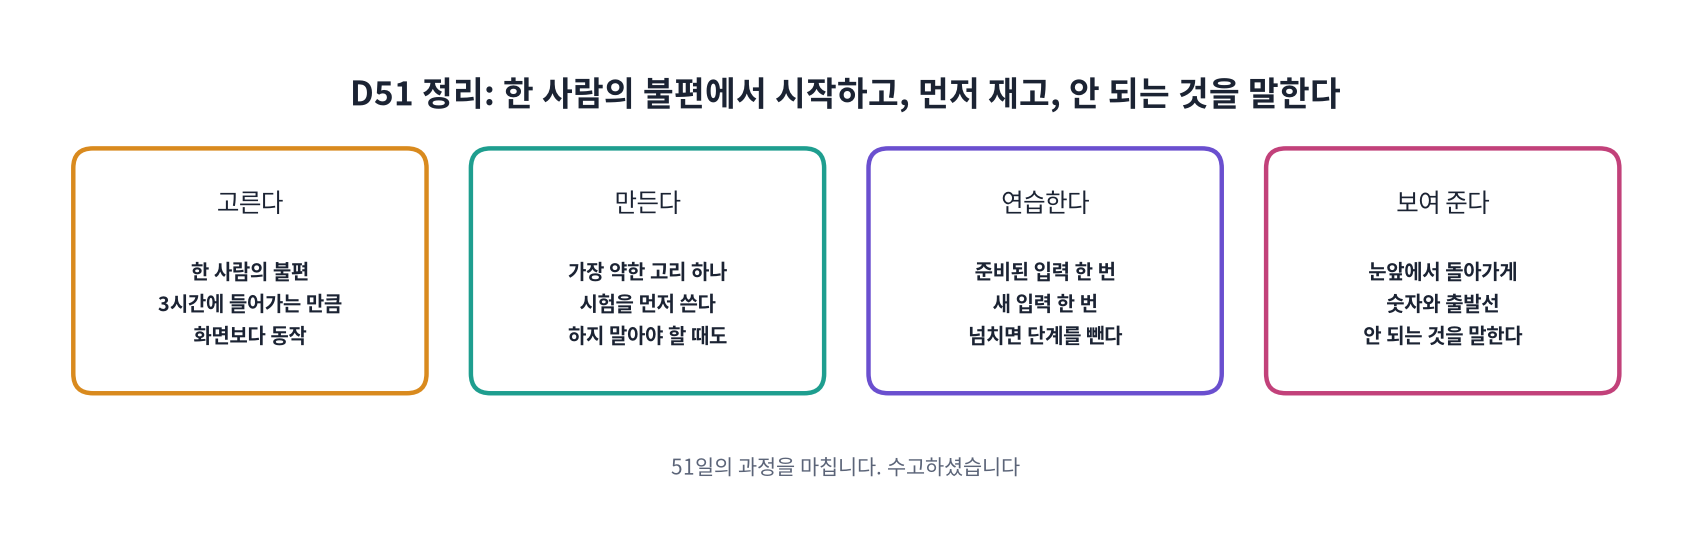

| 오늘 한 일 | 배운 것 |
|---|---|
| 부품과 출발선 | 불을 켜기 전에 냉장고를 연다. 부품은 멀쩡한데 잇는 곳이 모자랐다 |
| 한 장 기획서 | 한 사람의 불편에서 시작한다. 3시간에 들어가는 만큼만 고른다 |
| 핵심 함수 | 견주기 전에 같은 모양으로 · 글의 구조를 읽는다 · 가장 가까운 것이 충분히 가까운가 |
| 시험 | 해야 할 일과, 하지 말아야 할 때 안 하는지를 함께 본다 |
| 리허설 | 준비된 입력으로 한 번, 새 입력으로 한 번. 넘치면 단계를 뺀다 |
| 데모데이 | 보는 사람의 눈과 스스로 잰 숫자는 서로를 대신하지 못한다. 안 되는 것을 말한다 |

**오늘의 산출물**: 팀 코드 · 평가 코드 · `demo_card.md` · `demoday_result.json` · `my_51_days.md`

### ✍️ 과정 회고 (10분 · 아래에 직접 적어 보세요)

1. 51일 전의 나는 못 했고 **지금의 나는 할 수 있는 것** 한 가지는 무엇인가요?
2. 일곱 가지 프로젝트 형식(따라 만들기 · 인수 시험 · 성능 개선 · 경진대회 · 레드팀 · 제약 · 해커톤) 가운데 **나에게 가장 맞았던 것**은 무엇이고, 까닭은요?
3. 다음 달에 음성으로 무언가를 만든다면, **가장 먼저 잴 숫자**는 무엇인가요?

> ⚠️ **오늘 하지 않은 것**: 발음 평가(튜터는 낱말이 들렸는지만 봅니다. 발음의 좋고 나쁨을 재려면 발음 평가를 위한 모델이 따로 필요합니다), 번역(통역기는 문장집입니다. 실제 통역은 번역 모델이나 LLM을 씁니다), 실제 사람의 목소리(학습자와 회의 참석자는 합성한 목소리입니다), 마이크로 실시간 듣기(준비된 소리와 그 자리에서 합성한 소리를 넣었습니다), LLM(키 없이 끝까지 돌아가게 하려고 뺐습니다), 수료를 증명하는 문서(기념 카드는 기록일 뿐입니다. 수료증은 교육 기관이 발급합니다).

**51일 동안 수고하셨습니다.** 소리를 숫자로 바꾸는 데서 시작해, 받아쓰고, 말하고, 대화하고, 서비스로 올리고, 재고, 공격받고, 예산 안에 넣는 데까지 왔습니다. 도구와 모델의 이름은 내년이면 바뀝니다. 바뀌지 않는 것은 오늘도 한 일입니다. **한 사람의 불편에서 시작하고, 먼저 재고, 안 되는 것을 말하는 일**입니다.

> 🎬 **애니메이션 D51-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day51/animation.html#recap) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day51/worksheet.html) 25문항